# Цены краткосрочной аренды в Лондоне
## Прогноз и роль отзывов
**Главный вопрос:** насколько точно характеристики объявления позволяют предсказывать ночную цену предложения? **Экономическая гипотеза:** премия, связанная с более высоким рейтингом, больше при большем числе отзывов.

Один объект — одно объявление. Цель — непрерывная цена в GBP. OLS ниже означает обычную линейную регрессию **логарифма цены**, а не logistic regression. XGBRegressor решает ту же задачу регрессии. Мы не превращаем цену в метку «дорого/дёшево».

Ноутбук заново считает результаты из двух сохранённых снимков Inside Airbnb. Ранние результаты уже были изучены: это воспроизведение и ограниченное расширение анализа, а не новая проверка на нетронутых данных. План расширения: `analysis_plan.md`.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from helpers import analysis as A
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 50)
warnings.filterwarnings('ignore', message='Skipping features without any observed values')
warnings.filterwarnings('ignore', message='Found unknown categories')
ROOT = Path.cwd()
assert (ROOT / 'data/split.csv').exists(), 'Run from final-group-project/'
print('Python:', sys.version.split()[0], '| Seed:', A.SEED)
print('Plan SHA256:', __import__('hashlib').sha256((ROOT/'analysis_plan.md').read_bytes()).hexdigest())
def figure(name): display(Image(filename=str(A.FIG/f'{name}.png')))


Python: 3.12.7 | Seed: 20261016
Plan SHA256: d146a3e1d8ac8cbadd87decbc6e088e2ff2ca0ec3ab532b624623236aa35cf43


## 1. Экономическая задача и предшествующие работы
Такой прогноз может помочь хозяину сравнить своё предложение с похожими объектами в том же городе. Он не оценивает вероятность бронирования, выручку или оптимальную цену: в данных нет наблюдаемых сделок и реакции спроса.

Рейтинг 4,9 на основе 100 отзывов может быть более убедительным сигналом качества, чем тот же рейтинг на основе десяти. Проверяем именно **различие премий за одинаковое изменение рейтинга**. Конкурирующие объяснения: возраст объявления, спрос, ненаблюдаемое качество, отбор гостей и прошлые цены.

* **Gyódi & Nawaro (2021), Tourism Management 86, 104319.** В исследовании цен Airbnb в десяти европейских городах учитываются характеристики жилья и пространственные связи. Работа обосновывает внимание к местоположению; она не доказывает нашу гипотезу об отзывах. [Статья](https://doi.org/10.1016/j.tourman.2021.104319).
* **Fradkin, Grewal & Holtz (2021), Marketing Science 40(6), 1013–1029.** В эксперименте изменение порядка раскрытия отзывов изменило их количество и оценки. Поэтому рейтинг — результат поведения пользователей и правил платформы, а не чистое измерение качества. [Оригинальная аннотация](https://pubsonline.informs.org/doi/abs/10.1287/mksc.2021.1311).
* **Fradkin & Holtz (2021), авторский препринт.** Эксперимент со стимулированием первого отзыва не дал общего роста проданных ночей и выручки. Из большего числа отзывов нельзя автоматически вывести финансовый выигрыш. [Препринт и аннотация](https://arxiv.org/abs/2112.09783).

Обзор ограничен проверенными аннотациями и доступными методическими выдержками. Мы не заявляем академическую новизну и не выдаём собственную связь цен за результат этих работ.

## 2. Источники, аудит и две выборки
[Inside Airbnb](https://insideairbnb.com/get-the-data/), London, CC BY 4.0. Снимки [17 сентября](https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/listings.csv.gz) и [19 июня 2026](https://data.insideairbnb.com/united-kingdom/england/london/2026-06-19/data/listings.csv.gz). Метка выпуска и фактическая дата сбора строки различаются. Все хеши ниже вычисляются заново.

Основная прогнозная выборка сохраняет объявления с корректными координатами, хозяином и вместимостью, ценой £10–£2 000. Пропущенные цены не восстанавливаем. Для гипотезы дополнительно нужны entire home/private room, наблюдаемый рейтинг 3–5 и 1–500 отзывов. Из-за этого знаменатели различаются.

In [2]:
d, X, y, num, cat, ix, audit = A.audit()
display(pd.read_csv(A.OUT/'cohort_flow.csv'))
display(pd.DataFrame(audit['splits']).T)
display(pd.Series({k: audit[k] for k in ['raw_rows','raw_columns','raw_hosts','duplicates','missing_prices','all_empty_columns','currency_counts','quote_pairs','quote_matches']}))
display(pd.Series(audit['hashes'], name='SHA256'))


,cohort,listings,hosts
0,Raw September,91954,51348
1,Positive price + basic validity,59905,28981
2,Price £10–£2000,59635,28908
3,Rated hypothesis cohort,46553,23561


,rows,hosts
train,36331,17344
validation,11400,5782
holdout,11904,5782


raw_rows                      91954
raw_columns                      90
raw_hosts                     51348
duplicates                        0
missing_prices                32049
all_empty_columns                15
currency_counts      {'GBP': 60028}
quote_pairs                   59761
quote_matches                 59761
dtype: object

london_2026-06-19.csv.gz    f32fbf1bdd3a4fcdb58ffe901b4ac20d8614f77cd36f1e...
split.csv                   bd474ede43770b629676e9048d25960ee41646a7e018f0...
london_2026-09-17.csv.gz    8017870734a9bffa1b424937372e5f02f8c4a114e50605...
Name: SHA256, dtype: str

Символ `$` в текстовом поле цены вводит в заблуждение. Аудит исходных quote-payloads проверяет код валюты **GBP**; суммы в них используются только для сверки цели. Указанная цена — ночная цена для конкретного запрошенного периода, а не средняя годовая цена объекта. Во всех моделях учитываем месяц и день недели заезда, длину проживания, время до заезда и день сбора.

90 столбцов не равны 90 полезным независимым признакам. Пятнадцать целиком пусты. Семейства удобств извлекаются из одного списка amenities; dummy-переменные категорий не являются новыми источниками информации. Число ванных и факт совместного использования берём из `bathrooms_text`.

In [3]:
display(pd.read_csv(A.OUT/'raw_missingness.csv').head(25))
manifest = pd.read_csv(A.OUT/'feature_manifest.csv')
display(manifest.groupby('group').agg(inputs=('feature','size'), varying=('unique_values',lambda s: int((s>1).sum()))))
display(manifest)
print('Forbidden predictors:', audit['forbidden'])


,Unnamed: 0,missing_fraction
0,neighbourhood,1.000000
1,instant_bookable,1.000000
2,host_response_rate,1.000000
3,bathrooms,1.000000
4,host_acceptance_rate,1.000000
5,host_since,1.000000
6,host_thumbnail_url,1.000000
7,host_neighbourhood,1.000000
8,license,1.000000
9,host_total_listings_count,1.000000


,inputs,varying
group,,
Amenities,31,31
Booking context,8,7
Host,8,5
Location,4,4
Property,7,7
Reviews,7,7


,feature,unique_values,missing_fraction,group
0,accommodates,16,0.000000,Property
1,bedrooms,14,0.000386,Property
2,beds,25,0.025136,Property
3,bathroom_count,25,0.001627,Property
4,bathroom_shared,2,0.001526,Property
...,...,...,...,...
60,host_identity_verified,2,0.000000,Host
61,instant_bookable,1,0.000000,Booking context
62,quote_month,12,0.000000,Booking context
63,quote_weekday,7,0.000000,Booking context


Forbidden predictors: ['price', 'price_quote_raw', 'price_quote_total_price', 'price_quote_price_per_night', 'review_scores_value', 'review_scores_location', 'host_id', 'id', 'estimated_revenue_l365d', 'estimated_occupancy_l365d']


Числовые пропуски: медиана обучающей выборки и индикатор пропуска. Категории: one-hot encoding — отдельные 0/1-столбцы; редкие категории объединяются по train, незнакомые при проверке не переобучают преобразование. Масштабирование также обучается только на train. Пустые числовые столбцы не создают искусственной информации.

Из входов исключены IDs, суммы quote, копии цены, оценки occupancy/revenue и review_scores_value/location. В гипотезе другие подоценки качества исключены из основных контролей и добавлены только в записанной проверке.

Разбиение задаётся **хозяином**, а не строкой: его объекты не могут одновременно попасть в train и test. Сентябрьский test был нетронут в исходном прогнозном пилоте, но затем многократно использовался для поиска гипотез. Новая случайная разбивка не вернула бы ему этот статус.

## 3. Описательные графики
Графики этой части используют только train. Они показывают необработанные распределения и медианы, без поправки на качество и состав объектов. Логарифм сжимает правый хвост и делает ошибки в относительных ценах сопоставимее.

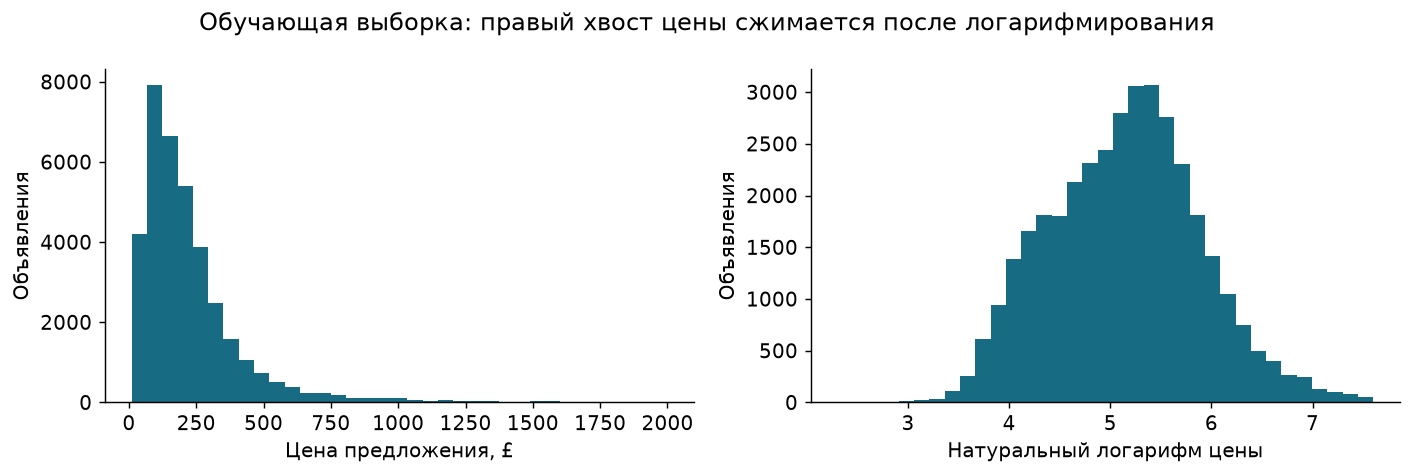

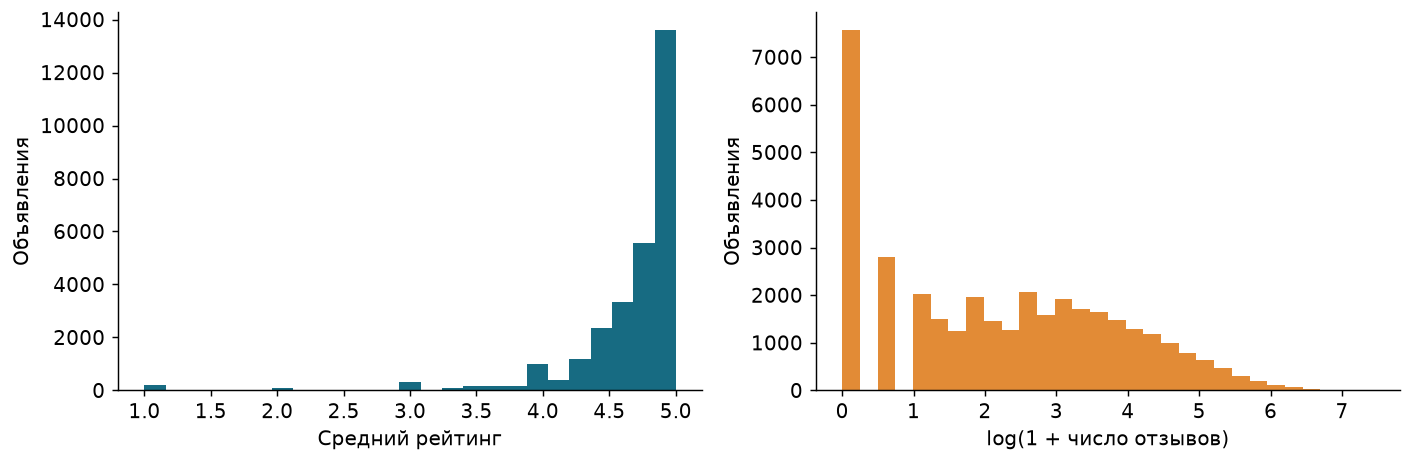

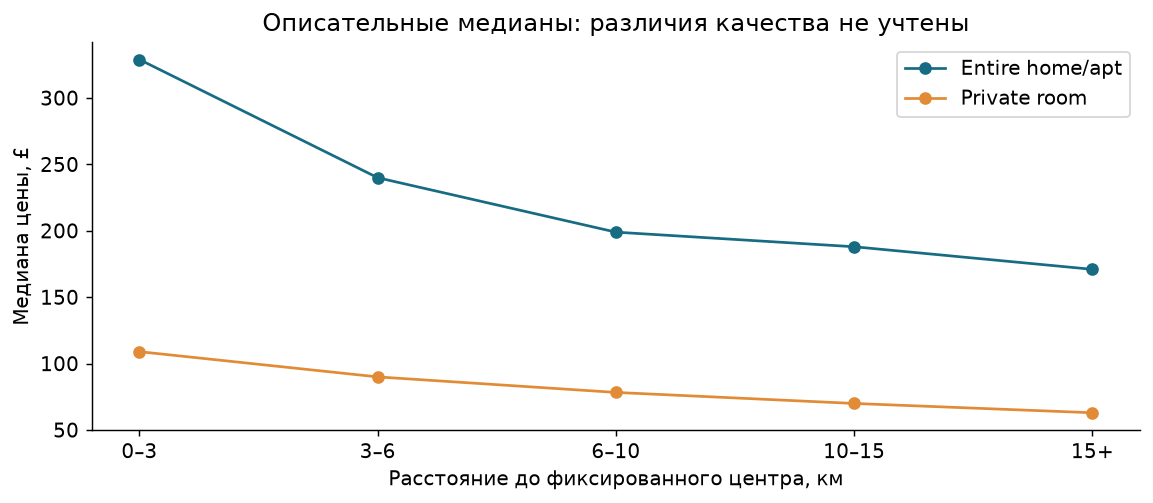

,room_type,distance_band,n,median_price
0,Entire home/apt,0–3,4659,329.000
1,Entire home/apt,3–6,8938,240.000
2,Entire home/apt,6–10,5511,199.000
3,Entire home/apt,10–15,3556,188.000
4,Entire home/apt,15+,1987,171.000
5,Private room,0–3,1303,109.000
6,Private room,3–6,2878,90.000
7,Private room,6–10,2962,78.315
8,Private room,10–15,2477,70.000
9,Private room,15+,1879,63.000


In [4]:
location = A.eda(d, X, ix)
figure('price_distributions')
figure('review_distributions')
figure('location_medians')
display(location)


## 4. OLS: меняется ли премия за рейтинг с числом отзывов?

Обозначим $r=rating-4.8$, $l=\log(1+reviews)-\log(11)$. Оцениваем

$$\log(price)=\alpha+a r+b l+c r l+X\gamma+\varepsilon.$$

Контроли: размер и тип жилья, удобства, характеристики хозяина, правила и даты бронирования, частота отзывов и местоположение. Полный список сохраняется в `results/ols/september/controls.json`.

При $n$ отзывах переход 4,7 → 4,9 равен $d(n)=0.2[a+c(\log(1+n)-\log(11))]$ в лог-цене; премия в процентах — $100(e^{d(n)}-1)$. Разность двух контрастов проверяется напрямую, через **полную ковариационную матрицу**, то есть с учётом совместной неопределённости коэффициентов. Стандартные ошибки объединяют объекты одного хозяина в кластер; критические значения используют t-распределение с числом кластеров минус один.

Каждая регрессия train/validation/старого test/июня оценивается отдельно. Это проверки статистической связи, а не предсказания обученной на train модели.

analyse.py 14.3 seconds


replicate.py 15.7 seconds


shape_september.py 13.1 seconds


shape_june.py 14.6 seconds


,term,coefficient,se,ci_low,ci_high,p_two_sided,n,hosts
0,rating_centered,0.222655,0.013044,0.197086,0.248224,1.126582e-64,28152,14088
1,log_reviews_centered,-0.015251,0.004015,-0.023121,-0.007381,1.462561e-04,28152,14088
2,rating_review_interaction,0.106919,0.008431,0.090392,0.123445,1.190950e-36,28152,14088


,hypothesis,spec,split,n,hosts,clusters,composite_p,all_directions,all_cis_expected,p_adjusted_21,supported,analysis
0,R,primary,train,28152,14088,14088,1.190950e-36,True,True,2.500994e-35,True,september
1,R,primary,validation,8887,4705,4705,3.733348e-15,True,True,7.840032e-14,True,september
2,R,primary,holdout,9514,4768,4768,3.370223e-22,True,True,7.077467e-21,True,september
21,R,primary,june,47533,24259,24259,2.028864e-76,True,True,4.260614e-75,True,june
22,R,new_hosts,june,3143,2440,2440,3.403068e-05,True,True,7.146443e-04,True,june


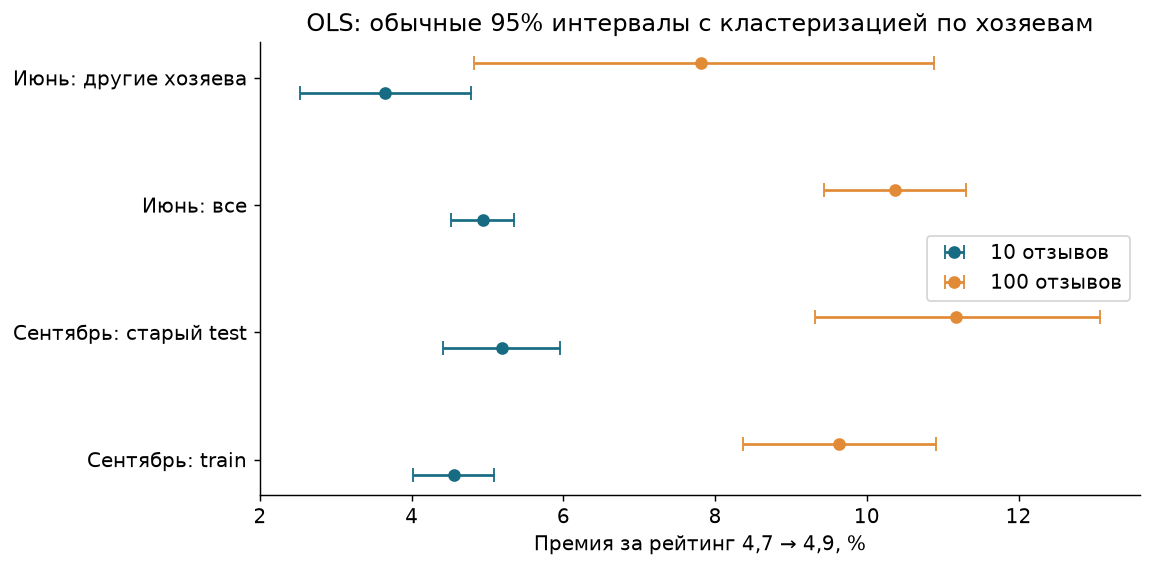

In [5]:
ols_tests, ols_contrasts, ols_coefficients = A.inference()
primary = ols_coefficients.query("analysis == 'september' and fit == 'R__primary__train'")
display(primary[['term','coefficient','se','ci_low','ci_high','p_two_sided','n','hosts']])
display(ols_tests.query("spec in ['primary','new_hosts']"))
figure('ols_contrasts')


Составная гипотеза требует одновременно положительного наклона рейтинга при 100 отзывах и большего наклона при 100, чем при 10. Берём максимум **двух двусторонних p-values**, затем `min(1, 21 × p)` по ранее учитывавшимся 21 содержательной гипотезе. Требуются оба положительных знака.

Обычные 95% интервалы ниже не исправлены на 21 тест. Поправка не устраняет весь риск адаптивного поиска. Разница премий в процентных пунктах и отношение ценовых множителей — разные величины: отношение равно `exp(d100 − d10) − 1`.

In [6]:
components = pd.read_csv(A.OUT/'ols_components.csv')
display(components.query("analysis=='september' and spec=='primary'")[['split','component','coefficient','se','ci_low','ci_high','p_two_sided']])
display(ols_contrasts.query("spec in ['primary','new_hosts']")[['analysis','spec','split','comparison','pct_change','pct_ci_low','pct_ci_high']])
z = ols_contrasts.query("analysis=='september' and spec=='primary' and split=='holdout'").set_index('comparison')
print('Difference in percentage points:', z.loc['rating_plus_02_at_100_reviews','pct_change']-z.loc['rating_plus_02_at_10_reviews','pct_change'])
print('Relative multiplier, %:', z.loc['rating_premium_ratio_100_vs_10','pct_change'])
display(ols_tests[['analysis','spec','split','n','hosts','composite_p','p_adjusted_21','supported']])


,split,component,coefficient,se,ci_low,ci_high,p_two_sided
0,train,rating_slope_at_100_reviews,0.459718,0.029593,0.401711,0.517724,5.666521e-54
1,train,rating_slope_100_minus_10,0.237063,0.018694,0.200420,0.273705,1.190950e-36
2,validation,rating_slope_at_100_reviews,0.448057,0.043175,0.363414,0.532700,5.814792e-25
3,validation,rating_slope_100_minus_10,0.224781,0.028490,0.168928,0.280634,3.733348e-15
4,holdout,rating_slope_at_100_reviews,0.529926,0.043081,0.445467,0.614385,2.957399e-34
5,holdout,rating_slope_100_minus_10,0.277200,0.028469,0.221388,0.333012,3.370223e-22


,analysis,spec,split,comparison,pct_change,pct_ci_low,pct_ci_high
0,september,primary,train,rating_plus_02_at_10_reviews,4.553738,4.020442,5.089768
1,september,primary,train,rating_plus_02_at_100_reviews,9.630295,8.365793,10.909552
2,september,primary,train,rating_premium_ratio_100_vs_10,4.855453,4.089827,5.626710
3,september,primary,validation,rating_plus_02_at_10_reviews,4.566729,3.824729,5.314031
4,september,primary,validation,rating_plus_02_at_100_reviews,9.374913,7.538927,11.242245
5,september,primary,validation,rating_premium_ratio_100_vs_10,4.598197,3.436273,5.773174
6,september,primary,holdout,rating_plus_02_at_10_reviews,5.184435,4.418098,5.956395
7,september,primary,holdout,rating_plus_02_at_100_reviews,11.180537,9.318273,13.074525
8,september,primary,holdout,rating_premium_ratio_100_vs_10,5.700561,4.527257,6.887035
63,june,primary,june,rating_plus_02_at_10_reviews,4.934570,4.518310,5.352488


Difference in percentage points: 5.9961024632705415
Relative multiplier, %: 5.700560622022838


,analysis,spec,split,n,hosts,composite_p,p_adjusted_21,supported
0,september,primary,train,28152,14088,1.190950e-36,2.500994e-35,True
1,september,primary,validation,8887,4705,3.733348e-15,7.840032e-14,True
2,september,primary,holdout,9514,4768,3.370223e-22,7.077467e-21,True
3,september,quadratic_controls,train,28152,14088,1.551856e-37,3.258899e-36,True
4,september,quadratic_controls,holdout,9514,4768,2.930076e-21,6.153160e-20,True
5,september,equal_host_weights,train,28152,14088,1.356635e-45,2.848935e-44,True
6,september,equal_host_weights,holdout,9514,4768,2.825589e-17,5.933736e-16,True
7,september,borough_cluster,train,28152,14088,2.567285e-17,5.391299e-16,True
8,september,borough_cluster,holdout,9514,4768,2.267926e-11,4.762644e-10,True
9,september,middle_price_range,train,27908,14010,1.584974e-37,3.328445e-36,True


**Важное исключение:** сентябрьская within-host проверка на старом test не проходит строгую поправку. Здесь сравниваются разные объекты одного хозяина, остаются только хозяева с несколькими объектами. Это более узкая выборка. Нельзя говорить, что все проверки прошли.

Июнь — более ранний снимок того же города. «Другие хозяева» означают отсутствие ID хозяина **во всём** сыром сентябрьском файле, включая объекты без цены. Это убирает совпадение хозяев, но не общие городские условия. Спецификация была записана до первоначального анализа июня; теперь и июнь уже изучен. Проверки кривизны основных связей и рейтингов 4,5–5 были дополнительной диагностикой после результата, не независимым подтверждением.

In [7]:
june = pd.read_csv(A.OUT/'ols/june/membership.csv')
raw_september_hosts = set(pd.read_csv(ROOT/'data/london_2026-09-17.csv.gz',usecols=['host_id']).host_id)
assert not set(june.loc[june.new_host,'host_id']) & raw_september_hosts
display(pd.DataFrame([{'cohort':'June all','n':len(june),'hosts':june.host_id.nunique()}, {'cohort':'June other hosts','n':int(june.new_host.sum()),'hosts':june.loc[june.new_host,'host_id'].nunique()}]))
display(ols_tests.loc[~ols_tests.supported])


,cohort,n,hosts
0,June all,47533,24259
1,June other hosts,3143,2440


,hypothesis,spec,split,n,hosts,clusters,composite_p,all_directions,all_cis_expected,p_adjusted_21,supported,analysis
12,R,host_fixed_effects,holdout,5932,1186,1186,0.015096,True,True,0.317018,False,september


## 5. Прогноз: одинаковые данные и честное сравнение
Сравниваем медиану лог-цены train, OLS, Ridge, маленькое дерево, Random forest и XGBRegressor. Ridge штрафует большие коэффициенты; его коэффициентам не приписываем обычные OLS p-values. Дерево делит объекты на группы, лес усредняет деревья, boosting последовательно исправляет ошибки.

Небольшая сетка заранее записана в плане: Ridge α = 1, 10, 100; XGBoost глубина 3 или 5. Остальные настройки фиксированы. Выбираем по **validation MAE лог-цены**, не по test и не по июню. После выбора модели остаются обученными на исходном train.

MAE(log price) — средняя абсолютная ошибка натурального логарифма цены, без валютных единиц. GBP MAE — средняя абсолютная ошибка в фунтах. R² сравнивает квадрат ошибки лог-прогноза с разбросом лог-цен. Обратное преобразование — `exp(predicted log price)`, без поправки на смещение; это не гарантированная оценка условного среднего цены.

Prediction: OLS {}


Prediction: Ridge {'alpha': 1}


Prediction: Ridge {'alpha': 10}


Prediction: Ridge {'alpha': 100}


Prediction: Small tree {'max_depth': 5, 'min_samples_leaf': 50}


...

Prediction: XGBoost {'max_depth': 3, 'n_estimators': 300, 'learning_rate': 0.05, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 10}


Prediction: XGBoost {'max_depth': 5, 'n_estimators': 300, 'learning_rate': 0.05, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 10}


,model,params,log_mae,gbp_mae,log_r2
0,OLS,{},0.281963,66.980566,0.729863
1,Ridge,"{""alpha"": 1}",0.281899,66.972188,0.729906
2,Ridge,"{""alpha"": 10}",0.281677,66.932520,0.730142
3,Ridge,"{""alpha"": 100}",0.281512,66.935335,0.730177
4,Small tree,"{""max_depth"": 5, ""min_samples_leaf"": 50}",0.333571,78.745115,0.643550
5,Random forest,"{""n_estimators"": 200, ""max_depth"": 14, ""min_sa...",0.270816,64.486312,0.744263
6,XGBoost,"{""max_depth"": 3, ""n_estimators"": 300, ""learnin...",0.259298,61.963846,0.766106
7,XGBoost,"{""max_depth"": 5, ""n_estimators"": 300, ""learnin...",0.250440,60.229343,0.778152


OLS                                                             {}
Ridge                                               {'alpha': 100}
Small tree                {'max_depth': 5, 'min_samples_leaf': 50}
Random forest    {'n_estimators': 200, 'max_depth': 14, 'min_sa...
XGBoost          {'max_depth': 5, 'n_estimators': 300, 'learnin...
dtype: object

,split,model,n,log_mae,gbp_mae,log_r2
0,train,Median,36331,0.599523,125.789767,-0.000962
1,train,OLS,36331,0.277567,66.428636,0.740399
2,train,Ridge,36331,0.278880,66.667370,0.736567
3,train,Small tree,36331,0.326012,76.892225,0.661609
4,train,Random forest,36331,0.206202,50.027050,0.850510
5,train,XGBoost,36331,0.226321,54.803308,0.823851
6,validation,Median,11400,0.607096,127.778369,-0.001500
7,validation,OLS,11400,0.281963,66.980566,0.729863
8,validation,Ridge,11400,0.281512,66.935335,0.730177
9,validation,Small tree,11400,0.333571,78.745115,0.643550


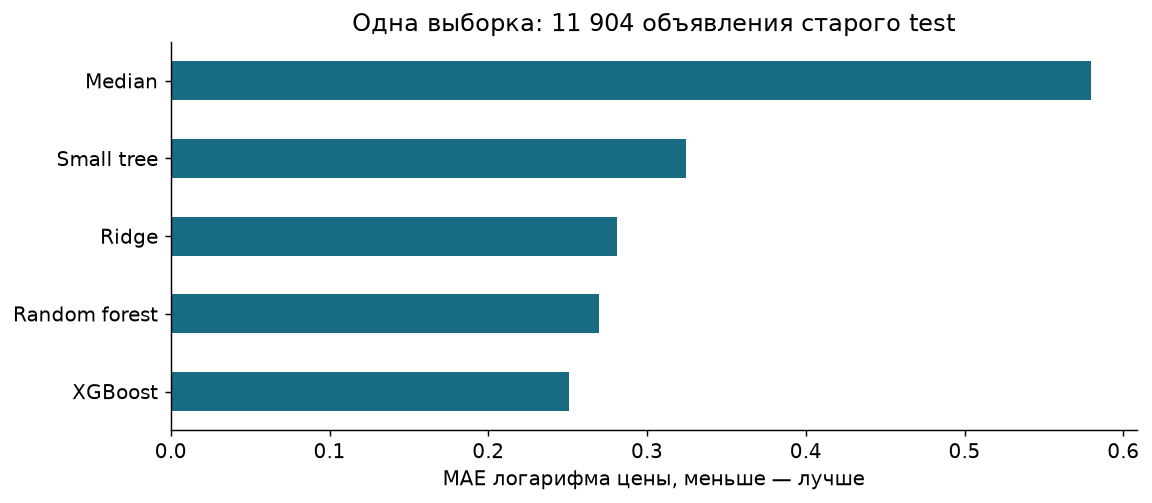

,comparison,log_mae_gain,relative_pct,ci_low,ci_high
0,XGBoost over Ridge,0.030282,10.763219,0.025906,0.034660
1,XGBoost over Random forest,0.018769,6.955795,0.015115,0.022859


In [8]:
pre, models, matrices, model_scores, predictions = A.prediction(d, X, y, num, cat, ix)
display(pd.read_csv(A.OUT/'tuning.csv'))
display(pd.read_json(A.OUT/'selected_settings.json',typ='series'))
display(model_scores)
figure('model_scores')
paired = A.bootstrap_errors(predictions['holdout'])
display(paired)


Bootstrap здесь повторно выбирает хозяев и сравнивает ошибки **фиксированных** прогнозов. Интервал учитывает зависимость объектов одного хозяина, но не неопределённость всего обучения, настроек или будущего города. Статистическая разница ошибок сама по себе не задаёт коммерчески полезный порог.

## 6. Проверяем устойчивость прогноза и пользу отзывов

В этом разделе мы меняем сначала разбиение данных, затем набор признаков. В первом эксперименте хотим понять, сохраняется ли преимущество XGBoost на других группах объявлений. Во втором проверяем, насколько отзывы помогают предсказывать цену.

### 6.1. Сохраняется ли результат при другом разбиении?

Одна проверочная выборка может оказаться легче или сложнее другой. Поэтому сравнение моделей повторяем трижды. Объединяем исходные train и validation и распределяем хозяев по трём группам. Обучаем модели на двух группах, проверяем на оставшейся. Повторяем это для каждой группы. Все объявления одного хозяина остаются вместе, поэтому модель каждый раз проверяется на хозяевах, которых не видела при обучении. Такой способ называется GroupKFold.

В каждом повторе заново готовим данные и обучаем модели. Например, значения для заполнения пропусков рассчитываем только по обучающим объявлениям. Настройки моделей сохраняем: Ridge с α=10 и XGBoost с глубиной деревьев 5. Параметр α задаёт силу ограничения коэффициентов Ridge; в этом эксперименте его заново не подбираем. Вложенной кросс-валидации (nested CV), с отдельным внутренним подбором настроек, здесь нет.

Получились следующие ошибки. Log MAE означает среднюю абсолютную ошибку логарифма цены; меньшее число соответствует более точному прогнозу.

| Проверочная группа | Ridge, α=10 | XGBoost, depth=5 |
|---|---:|---:|
| 1 | 0,2870 | 0,2560 |
| 2 | 0,2819 | 0,2540 |
| 3 | 0,2808 | 0,2488 |
| Среднее | 0,2832 | 0,2529 |

XGBoost точнее во всех трёх группах. Его средняя ошибка примерно на 10,7% ниже ошибки Ridge. Значит, преимущество XGBoost сохраняется при смене разбиения.

На графике сопоставляем эти средние с исходной validation при тех же настройках моделей. У Ridge ошибка выросла с 0,2817 до 0,2832, то есть на 0,55%. У XGBoost она выросла с 0,2504 до 0,2529, или на 0,99%. Ухудшение небольшое; отдельные группы дают ошибку даже ниже исходной validation.

В обоих способах данные разделены по хозяевам. При этом в каждом повторе GroupKFold для обучения доступно 31 820–31 821 объявление вместо исходных 36 331, а состав проверочных объявлений меняется. Поэтому разницу ошибок нельзя целиком объяснить способом разбиения или назвать доказательством переобучения. Эти данные уже изучались: эксперимент проверяет устойчивость результата, но не заменяет проверку на новых данных.

### 6.2. Что дают рейтинг и отзывы?

Теперь оставляем одну и ту же выборку и меняем информацию, которую получает модель. Так можно проверить, помогают ли отзывы сверх уже известных характеристик жилья, хозяина, местоположения и условий бронирования.

Для OLS сравниваем три варианта. Сначала используем только эти характеристики. Затем добавляем рейтинг, log(1 + число отзывов) и частоту отзывов. Число отзывов показывает, сколько их накопилось всего, а частота показывает, сколько отзывов приходится на месяц.

В третьем варианте добавляем взаимодействие рейтинга и log-числа отзывов. Оно позволяет премии за рейтинг зависеть от количества отзывов. Например, одна и та же разница между рейтингами 4,7 и 4,9 может соответствовать разной разнице в цене при 10 и при 100 отзывах. Без взаимодействия линейная модель предполагает одинаковую относительную премию за рейтинг при любом числе отзывов. Остальные признаки совпадают с основной регрессией из раздела 4.

Для XGBoost сравниваем два варианта: без этих признаков об отзывах и с ними. Отдельное произведение признаков не добавляем: деревья сами могут сначала разделить объявления по числу отзывов, а затем по рейтингу и тем самым учесть их совместное влияние.

Все ошибки в следующей таблице рассчитаны на одних и тех же 9 514 объявлениях старой проверочной выборки. Модели обучаются на соответствующих 28 152 объявлениях train. Поэтому разницу в качестве здесь не объяснить тем, что одна модель получила для проверки более простые объекты.

| Модель и доступная информация | Log MAE | MAE в фунтах |
|---|---:|---:|
| OLS: характеристики объявления | 0,2592 | £55,62 |
| OLS: + рейтинг, число и частота отзывов | 0,2489 | £54,13 |
| OLS: + взаимодействие | 0,2457 | £53,51 |
| XGBoost: характеристики объявления | 0,2427 | £52,42 |
| XGBoost: + рейтинг, число и частота отзывов | 0,2293 | £50,44 |

Информация об отзывах улучшает прогноз обеих моделей. У XGBoost log MAE снижается примерно на 5,5%, а средняя ошибка в фунтах уменьшается с £52,42 до £50,44.

В OLS добавление взаимодействия после рейтинга и отзывов даёт ещё 1,28% снижения log MAE. В фунтах ошибка уменьшается с £54,13 до £53,51. Это небольшое дополнительное улучшение: взаимодействие помогает прогнозу, но большая часть выигрыша в этой последовательности появляется уже после добавления самих показателей об отзывах.

Здесь мы оцениваем пользу признаков для прогноза. Значимость коэффициента взаимодействия проверяется отдельно в разделе 4. Чтобы связать улучшение прогноза именно с доверием гостей к рейтингу, этого сравнения недостаточно: отзывы также отражают спрос, возраст объявления и качество жилья. Приведённые результаты относятся к уже изученной выборке.


CV 1 Ridge


CV 1 XGBoost


CV 2 Ridge


CV 2 XGBoost


CV 3 Ridge


CV 3 XGBoost


,fold,model,n_train,n_validation,log_mae,gbp_mae,log_r2
0,1,Ridge,31820,15911,0.286962,70.683930,0.730748
1,1,XGBoost,31820,15911,0.255972,63.719893,0.777314
2,2,Ridge,31821,15910,0.281868,63.379914,0.718045
3,2,XGBoost,31821,15910,0.253978,57.960199,0.765669
4,3,Ridge,31821,15910,0.280836,69.757774,0.734073
5,3,XGBoost,31821,15910,0.248796,61.344013,0.785215


log_mae              gbp_mae          
             mean       std       mean       std
model                                           
Ridge    0.283222  0.003280  67.940540  3.976672
XGBoost  0.252915  0.003704  61.008035  2.894509

,model,metric,single_validation,grouped_cv_mean,error_increase_pct
0,Ridge,log_mae,0.281677,0.283222,0.548439
1,Ridge,gbp_mae,66.932520,67.940540,1.506024
2,XGBoost,log_mae,0.250440,0.252915,0.988277
3,XGBoost,gbp_mae,60.229343,61.008035,1.292879


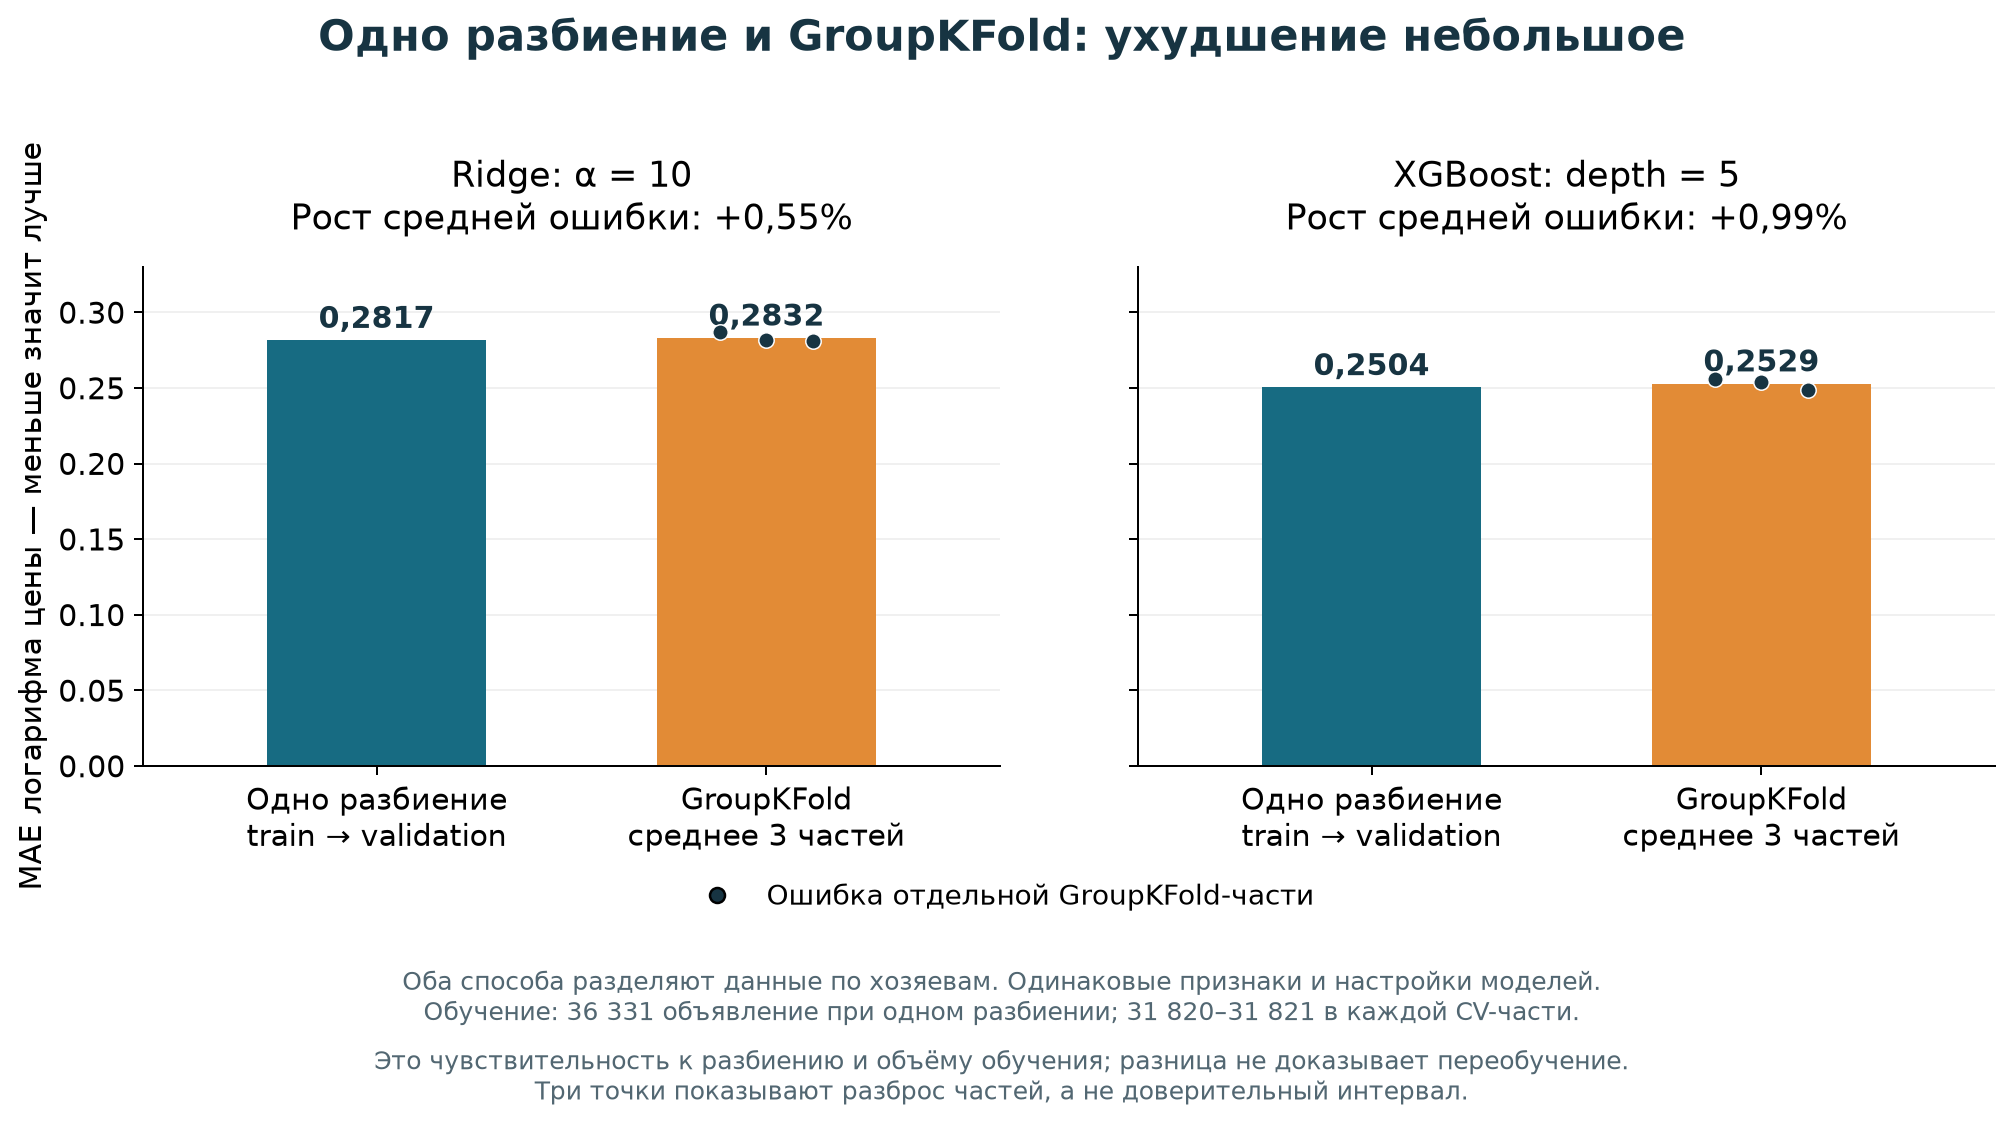

,model,features,split,n,log_mae,gbp_mae,log_r2
0,OLS,Non-review,train,28152,0.255173,57.462244,0.764815
1,OLS,Non-review,validation,8887,0.261817,59.015551,0.755771
2,OLS,Non-review,holdout,9514,0.259204,55.618357,0.749769
3,OLS,Review main,train,28152,0.245248,55.519857,0.780279
4,OLS,Review main,validation,8887,0.250186,56.870640,0.772207
5,OLS,Review main,holdout,9514,0.248854,54.131073,0.765463
6,OLS,Review interaction,train,28152,0.243204,55.092764,0.783115
7,OLS,Review interaction,validation,8887,0.248503,56.544910,0.774400
8,OLS,Review interaction,holdout,9514,0.245676,53.506028,0.769546
9,XGBoost,Non-review,train,28152,0.214179,48.777677,0.832839


Full training coefficient table: results/ols_full_training_coefficients.csv


,term,coefficient,cluster_se,ci_low,ci_high,p_two_sided
124,cat__neighbourhood_cleansed_Lambeth,-0.128781,0.048244,-0.223347,-0.034216,0.007609
125,cat__neighbourhood_cleansed_Lewisham,-0.112552,0.041762,-0.194412,-0.030693,0.007046
126,cat__neighbourhood_cleansed_Merton,-0.085700,0.056942,-0.197313,0.025914,0.132336
127,cat__neighbourhood_cleansed_Newham,0.047576,0.036159,-0.023302,0.118453,0.188290
128,cat__neighbourhood_cleansed_Redbridge,0.009858,0.043642,-0.075686,0.095402,0.821298
129,cat__neighbourhood_cleansed_Richmond upon Thames,0.083265,0.062252,-0.038758,0.205287,0.181068
130,cat__neighbourhood_cleansed_Southwark,-0.090178,0.044869,-0.178126,-0.002229,0.044470
131,cat__neighbourhood_cleansed_Sutton,-0.215404,0.064730,-0.342285,-0.088524,0.000878
132,cat__neighbourhood_cleansed_Tower Hamlets,0.031385,0.040130,-0.047274,0.110045,0.434170
133,cat__neighbourhood_cleansed_Waltham Forest,-0.055259,0.037180,-0.128136,0.017618,0.137231


In [9]:
cv = A.cv_experiment(d, X, y, num, cat, ix)
display(cv)
display(cv.groupby('model')[['log_mae','gbp_mae']].agg(['mean','std']))
from helpers.split_comparison import plot_split_comparison
split_comparison = plot_split_comparison()
display(split_comparison[['model', 'metric', 'single_validation', 'grouped_cv_mean', 'error_increase_pct']])
figure('split_vs_groupkfold')
ablation, rated, rated_X, rated_models = A.ablation(d)
display(ablation)
print('Full training coefficient table:', 'results/ols_full_training_coefficients.csv')
display(pd.read_csv(A.OUT/'ols_full_training_coefficients.csv').tail(12))


На графике выше сравниваются одинаковые настройки моделей. Синие столбцы показывают исходную validation, оранжевые — среднюю ошибку трёх GroupKFold-частей. Точки показывают ошибки отдельных частей. Значения в таблице matched_ablation относятся ко второму эксперименту и рассчитаны на одной рейтинговой выборке.

Полная таблица коэффициентов включает стандартизованные числовые контроли и one-hot категории. При линейно зависимых контролях используется SVD-решение минимальной нормы; отдельные такие коэффициенты не имеют самостоятельной устойчивой интерпретации. Основные коэффициенты гипотезы выше рассчитаны в исходных единицах и проверены прямой полной регрессией.

## 7. Как XGBoost использует признаки

### 7.1. Перестановочная важность: без какой информации прогноз ухудшается

Здесь проверяем, на какие группы признаков опирается уже обученный XGBoost. Идея простая: если перепутать сведения о жилье между объявлениями и модель начнёт чаще ошибаться, значит, эти сведения помогали ей делать прогноз. Метод называется **перестановочная важность признаков** (permutation importance). Мы перемешиваем сразу связанные столбцы, поэтому используем его групповой вариант — grouped permutation importance.

#### Что именно делаем

Берём 2 000 случайных объявлений из исходной проверочной выборки test. Используем основную модель XGBoost из раздела 5, обученную на полной прогнозной выборке train. Сначала получаем прогнозы на обычных данных и считаем log MAE: среднюю абсолютную разницу между настоящим и предсказанным логарифмом цены. На этих 2 000 объявлениях исходная ошибка равна **0,2476**. Чем меньше ошибка, тем точнее прогноз.

Затем по очереди проверяем шесть групп: характеристики жилья, местоположение, характеристики хозяина, удобства, отзывы и условия бронирования. Для каждой группы:

1. Берём исходные 2 000 объявлений и случайно переставляем между ними значения выбранной группы. Остальные признаки и настоящую цену каждого объявления сохраняем.
2. Снова получаем прогнозы той же моделью. XGBoost не переобучаем; правила заполнения пропусков и обработки категорий тоже остаются прежними.
3. Считаем новую ошибку и вычитаем исходную: **важность группы = log MAE после перемешивания − исходная log MAE**.
4. Повторяем перемешивание пять раз и усредняем прирост ошибки. Перед проверкой следующей группы возвращаем исходные данные: искажения не накапливаются.

Например, при проверке местоположения квартира A получает район и координаты квартиры B. Характеристики жилья и настоящая цена остаются от A. Так разрушается соответствие между местоположением и ценой. Если модель использовала это соответствие, её прогнозы должны стать менее точными.

Все столбцы внутри группы перемещаются вместе, одним порядком строк. Поэтому координаты и район приходят из одного объявления. Категории превращаются в отдельные столбцы с нулями и единицами (one-hot) уже после перестановки, с помощью ранее обученного преобразования. Это сохраняет согласованность признаков внутри группы.

#### Что получилось

В таблице показаны средние результаты пяти перестановок. Исходная ошибка для всех строк одна и та же — 0,2476.

| Перемешанная группа | Прирост log MAE | Log MAE после перемешивания |
|---|---:|---:|
| Характеристики жилья (Property) | +0,3571 | 0,6047 |
| Местоположение (Location) | +0,1168 | 0,3644 |
| Условия бронирования (Booking context) | +0,0321 | 0,2797 |
| Удобства (Amenities) | +0,0297 | 0,2773 |
| Отзывы (Reviews) | +0,0259 | 0,2735 |
| Характеристики хозяина (Host) | +0,0047 | 0,2523 |

Сильнее всего прогноз портится при перемешивании характеристик жилья; следующая по величине потеря связана с местоположением. На этой выборке и при выбранной метрике модель особенно сильно опирается на эти две группы. Перемешивание характеристик хозяина меняет ошибку гораздо слабее. Это не означает, что хозяин не влияет на цену: часть связанной с ним информации может уже содержаться в других признаках.

В выводе кода `mean` — средний прирост ошибки, а `std` — разброс этого прироста между пятью перестановками. `std` показывает чувствительность к случайному перемешиванию для одной модели и одной выборки. Он не является доверительным интервалом и не учитывает неопределённость из-за обучения модели или выбора других объявлений.

#### Как понимать результат

Прирост 0,1168 для местоположения измеряется в единицах ошибки логарифма цены. Его нельзя читать как «местоположение повышает цену на 11,68%». Мы оцениваем потерю точности прогноза, а не ценовую премию или причинный эффект. Важности групп также не являются долями, которые должны складываться в 100%.

У метода есть два ограничения. Во-первых, связанные признаки могут подменять друг друга: если сведения об одном свойстве жилья есть в нескольких группах, перемешивание одной из них может дать небольшой прирост ошибки. Во-вторых, перемешивание создаёт непривычные сочетания, например характеристики одного жилья с местоположением другого. На таких сочетаниях модель может ошибаться сильнее. Совместная перестановка столбцов сохраняет связи внутри группы, но нарушает связи между группами.

Поэтому универсально самого достоверного способа оценить важность нет: разные методы отвечают на разные вопросы. Здесь мы проверяем зависимость точности готовой модели от группы входов. В эксперименте раздела 6 модели заново обучаются с признаками отзывов и без них: там проверяется, можно ли построить хороший прогноз без этой информации. А TreeSHAP в следующем разделе объясняет вклад признаков в отдельные прогнозы. Эти проверки дополняют друг друга; сами по себе они не доказывают экономический механизм.

[Описание permutation importance в документации scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html).


,mean,std
group,,
Property,0.357122,0.007042
Location,0.116800,0.003075
Booking context,0.032083,0.000996
Amenities,0.029684,0.001051
Reviews,0.025937,0.001195
Host,0.004722,0.001182


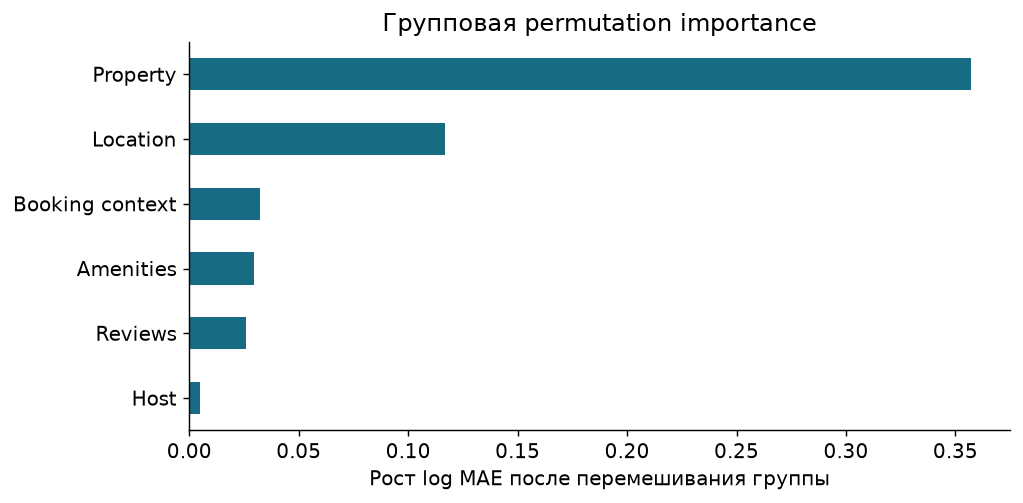

In [10]:
permutation = A.permutation(d, X, y, ix, pre, models['XGBoost'][1])
display(permutation)
figure('permutation')


### 7.2. TreeSHAP: почему модель предсказала именно такую цену

В разделе 7.1 мы портили входные данные и смотрели, насколько растёт ошибка. Здесь разбираем сами прогнозы: какие признаки сдвинули прогноз конкретного объявления вверх или вниз. Для этого используем TreeSHAP, способ разложить прогноз дерева или ансамбля деревьев на вклады признаков.

#### Как устроено объяснение

Берём 1 000 случайных объявлений из исходного test, без повторений. Для каждого получаем базовый прогноз и вклад каждого признака:

**Базовый прогноз + сумма вкладов = прогноз модели для объявления.**

Всё складывается в логарифмах цены. База здесь около 5,144, что после обратного преобразования соответствует примерно £171,46. Это точка отсчёта алгоритма объяснения, а не средняя рыночная цена и не цена квартиры «без характеристик». Положительный вклад сдвигает прогноз выше базы, отрицательный — ниже. Например, вклад +0,1 увеличивает log-прогноз на 0,1; он не означает прибавку £0,10.

Используем точный алгоритм TreeSHAP, встроенный в XGBoost (`pred_contribs=True`). Он учитывает, как обучающие наблюдения распределялись по путям деревьев; этот вариант называется `tree-path-dependent`. Объяснение поэтому зависит от обученной модели и выбранного способа учитывать связи признаков. Вклады всех категорий одного признака и его индикатора пропуска складываем обратно: район представлен одним итоговым вкладом, а не множеством отдельных столбцов.

Код проверяет равенство выше для каждого объявления. Максимальное расхождение около 0,000009 в log-шкале: вклады складываются в прогноз с точностью численных вычислений.

#### Как читать таблицу и графики

В таблице признаки упорядочены по среднему абсолютному вкладу. Берём величину вклада без знака, иначе положительные и отрицательные значения могли бы взаимно погаситься. Самые большие значения получились у типа комнаты (`room_type`, 0,197), расстояния до центра (`distance_km`, 0,157) и вместимости (`accommodates`, 0,133). Это признаки, которые в среднем сильнее сдвигают прогнозы в этой выборке. Значения не являются процентами важности.

На первом графике каждая точка — одно объявление. Справа от нуля признак повышает прогноз относительно базы, слева — понижает. Красный цвет означает большое значение числового признака, синий — маленькое; категории и пропуски показаны нейтрально. Например, по расположению красных точек у расстояния можно увидеть, как модель учитывает более удалённые объекты.

Два следующих графика подробнее показывают вклады рейтинга и числа отзывов. Цвет обозначает второй показатель: это помогает заметить, меняется ли вклад рейтинга при разном количестве отзывов. Такие рисунки описывают поведение модели. Они не дают p-value и не показывают, насколько изменится реальная цена после улучшения рейтинга. Для прямого сравнения модельных ответов используем следующий раздел.


room_type                    0.196712
distance_km                  0.157073
accommodates                 0.132795
bedrooms                     0.102682
bathroom_shared              0.070411
bathroom_count               0.065943
reviews_per_month            0.044236
quote_lead_days              0.038499
amenity_dishwasher           0.038357
review_scores_cleanliness    0.036159
quote_stay_nights            0.034364
longitude                    0.032239
quote_weekday                0.028765
property_type                0.023695
neighbourhood_cleansed       0.023577
dtype: float32

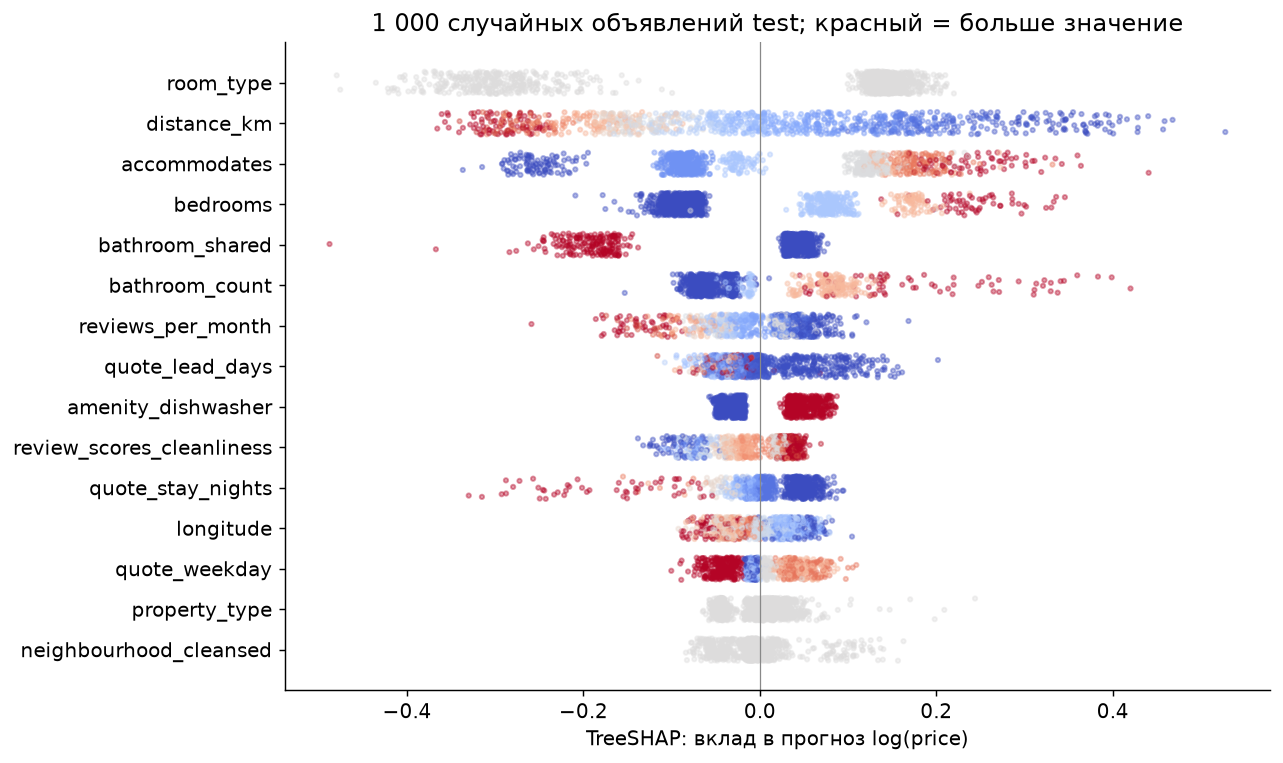

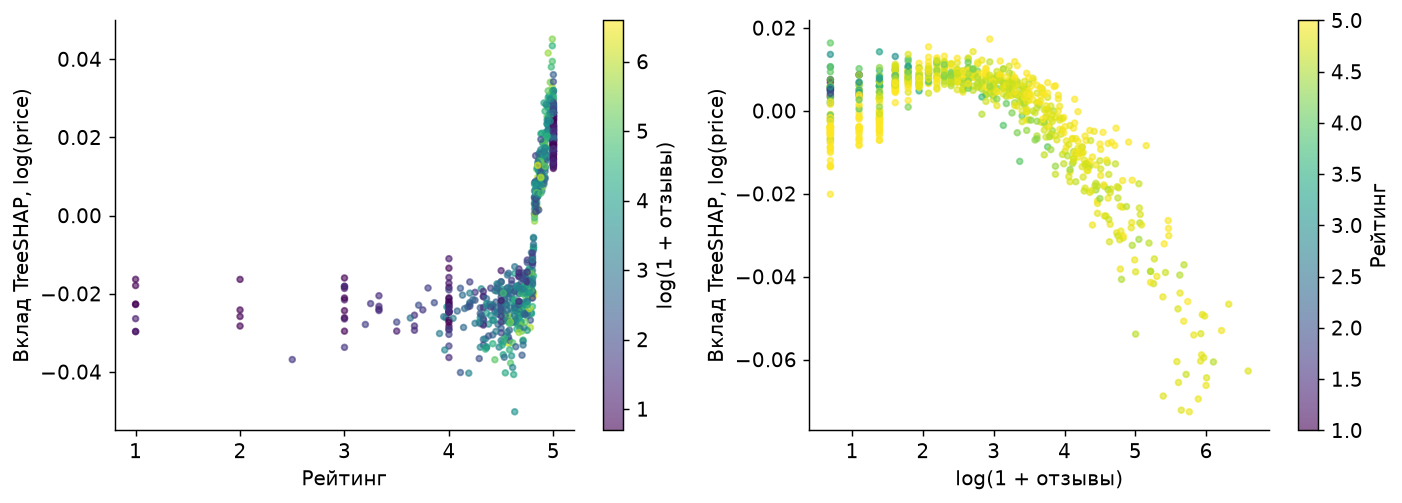

method                  Exact native XGBoost TreeSHAP, pred_contribs=T...
background              Training tree path frequencies (tree-path-depe...
sample                  Uniform 1000 rows without replacement from ori...
units                                                          log(price)
aggregation             one-hot and missingness indicators summed to s...
max_additivity_error                                             0.000009
dtype: object

In [11]:
shap_importance, shap_sample, shap_values = A.shap_analysis(d, X, y, ix, pre, models['XGBoost'][1])
display(shap_importance.head(15))
figure('shap_summary')
figure('shap_dependence')
display(pd.read_json(A.OUT/'shap_method.json',typ='series'))


#### 7.2.1. ICE: как модель реагирует на изменение 12 признаков

Теперь задаём прямой вопрос: что произойдёт с прогнозом конкретного объявления, если изменить один вход, сохранив остальные? Для каждого признака последовательно подставляем несколько значений. Из каждого прогноза вычитаем прогноз при первом значении на горизонтальной оси. Такая кривая называется центрированной ICE: она начинается с нуля и показывает ответ модели относительно выбранной точки отсчёта.

На рисунке тонкая серая линия — отдельное объявление XGBoost. Синяя линия объединяет ответы всех объектов панели; оранжевая пунктирная показывает ответ исходной OLS. Линия вверх означает повышение прогноза, вниз — снижение. Это не улучшение и ухудшение точности и не SHAP-вклады.

Используем исходную случайную выборку из 1 000 test-объявлений, затем для каждого признака оставляем целое жильё и отдельные комнаты с наблюдаемым значением внутри показанного диапазона. Для вместимости и спален дополнительно ограничиваем связанные характеристики; все правила записаны в коде. Поэтому число объектов `n` различается между панелями. Чтобы не перегрузить рисунок, показываем не более 120 индивидуальных линий на панели; сводные линии рассчитаны по всем её объектам.

Сравниваем 12 информативных или содержательно понятных признаков. Вертикальные оси везде измеряют относительное изменение прогноза в процентах, но их диапазоны различаются. По размеру наклона между разными панелями нельзя ранжировать важность: диапазоны изменений признаков и выборки тоже различаются. Сводная линия получена из средней разницы log-прогнозов, переведённой в проценты, а не из среднего индивидуальных процентов.

В углу каждой панели стрелки показывают доли объектов, у которых ответ между крайними значениями выше +0,5% или ниже −0,5%; остальные ответы близки к нулю. Это описательные доли, не статистические тесты. Данные и случай с ванными уже изучались: обзор наглядно организует исследование, а не является независимым обнаружением новой закономерности.


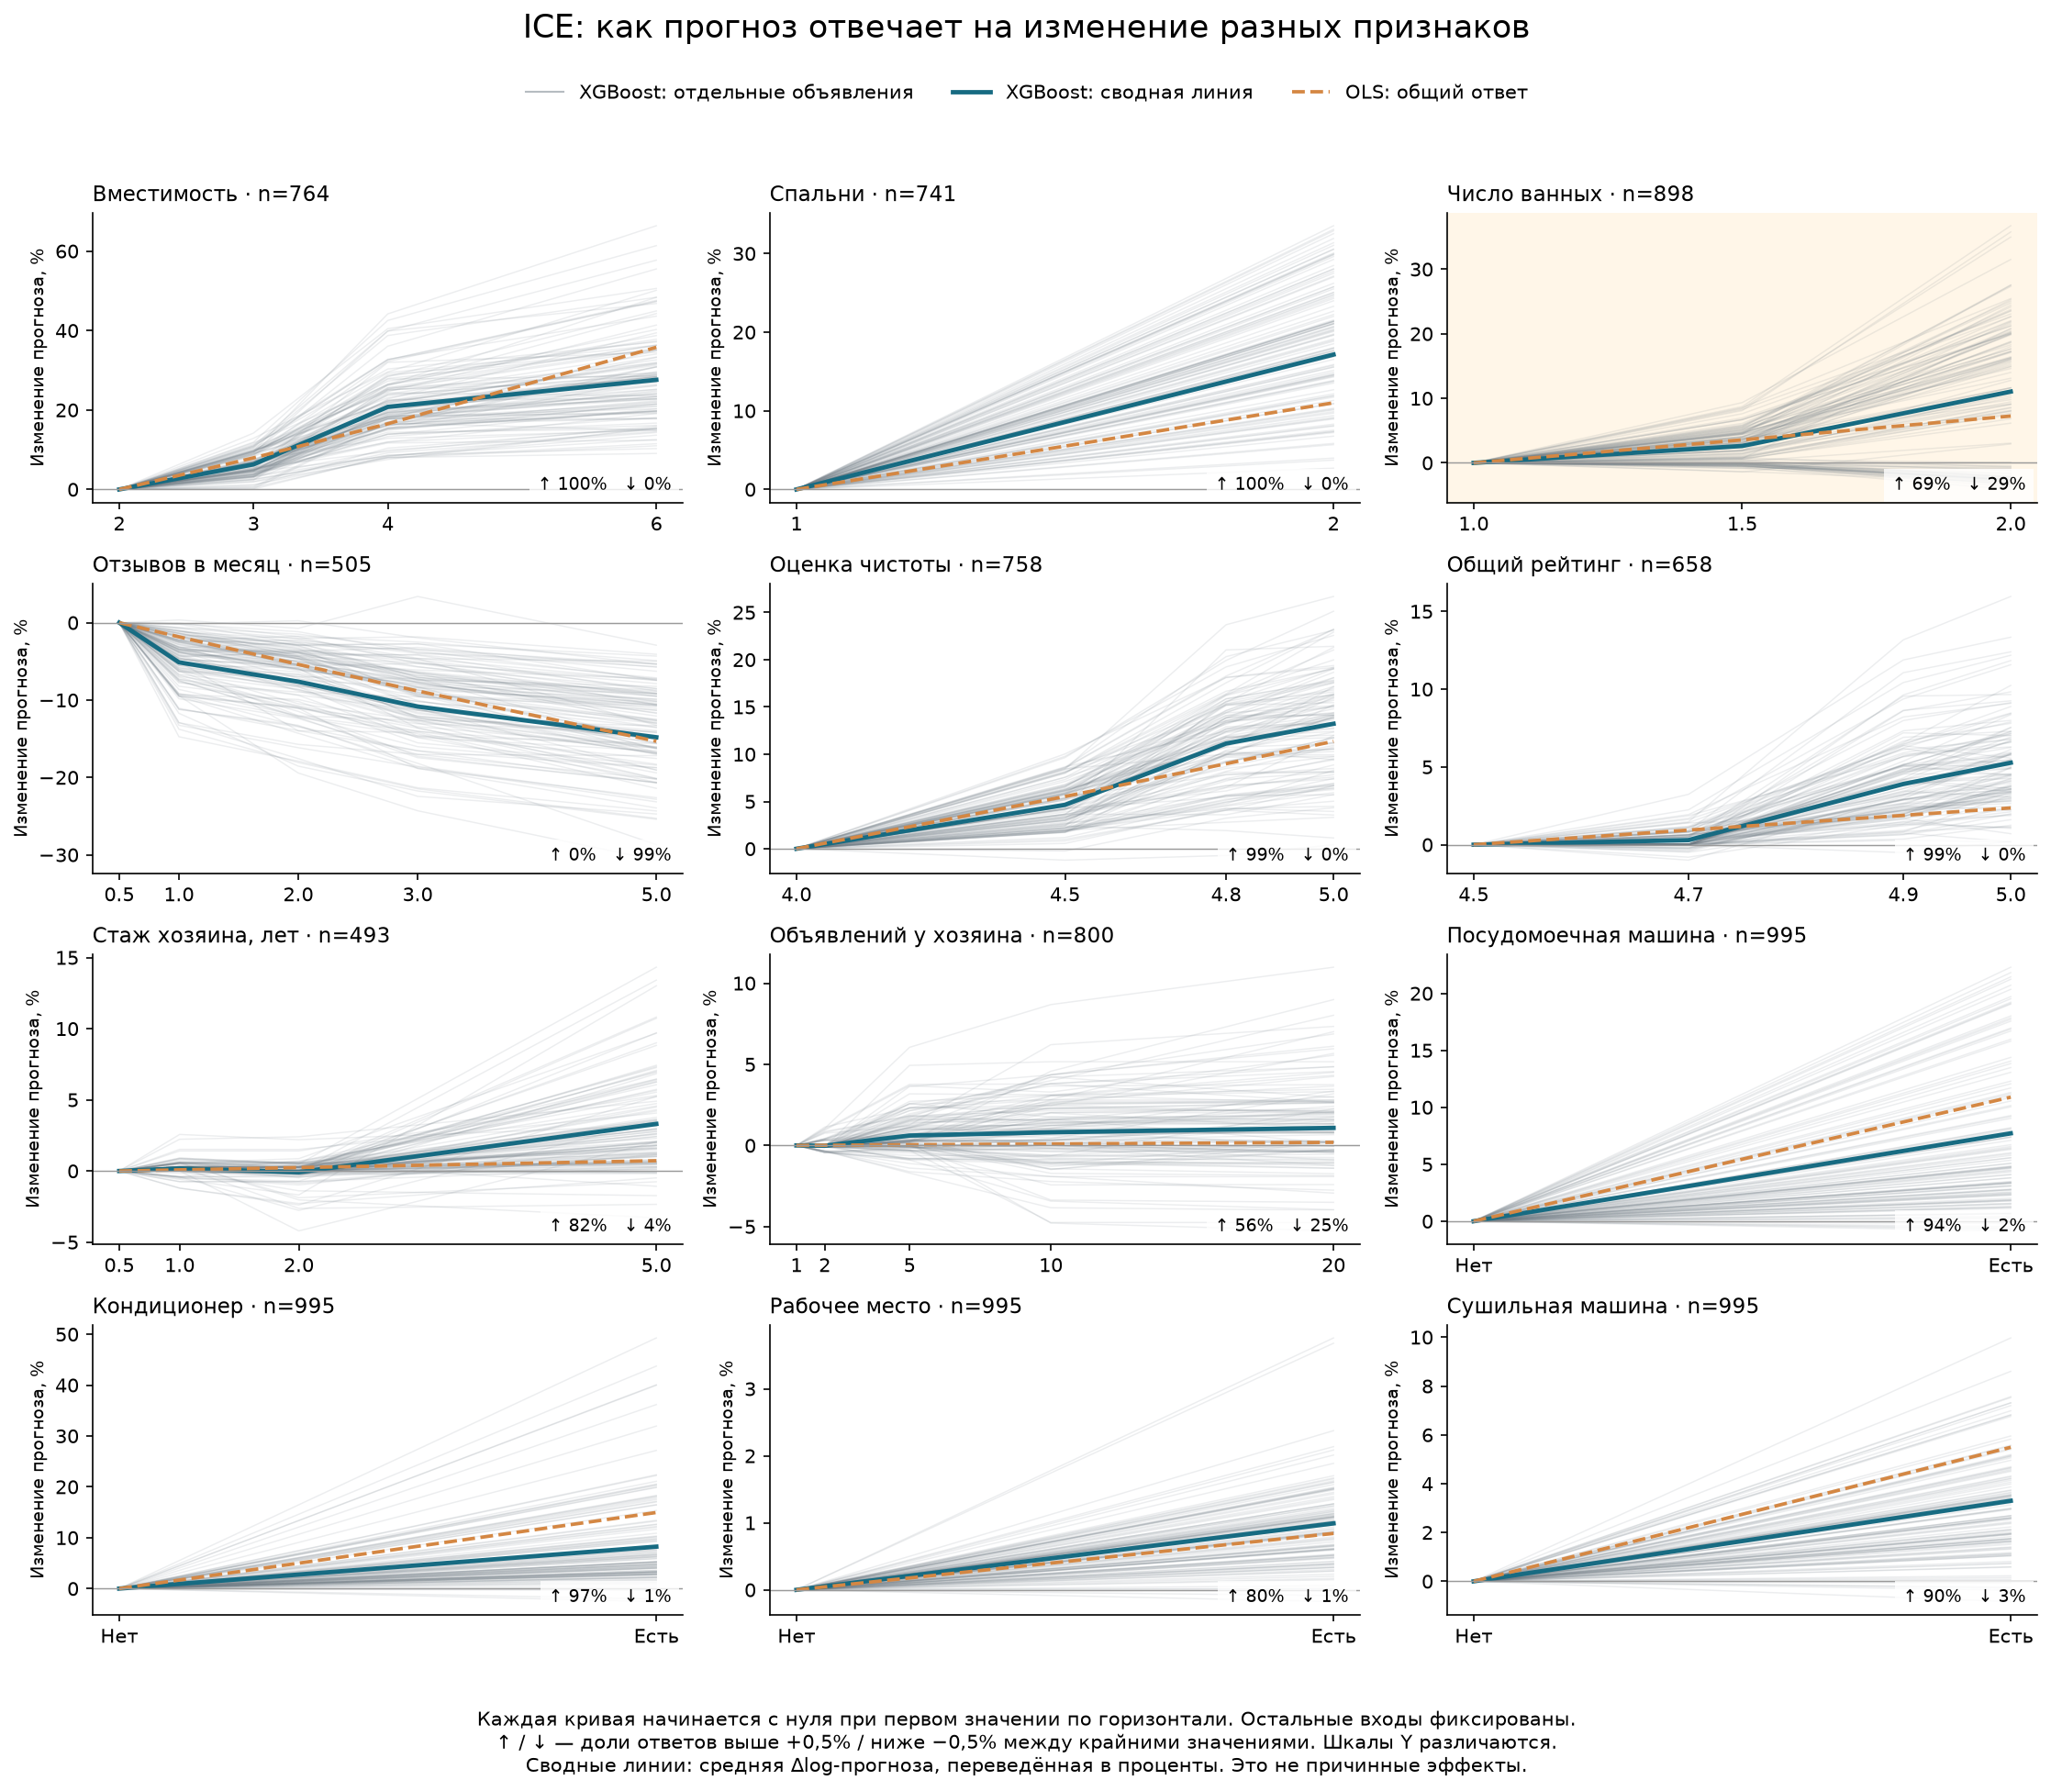

,Признак,От,До,Объектов,"XGBoost, %","OLS, %","Рост >0,5%, доля","Снижение >0,5%, доля"
0,Вместимость,2.00,6.0,764,27.59,35.78,100.00,0.00
3,Спальни,1.00,2.0,741,17.15,11.01,100.00,0.00
6,Число ванных,1.00,2.0,898,11.04,7.25,69.49,28.62
9,Отзывов в месяц,0.50,5.0,505,-14.81,-15.32,0.40,99.41
12,Оценка чистоты,4.00,5.0,758,13.22,11.36,99.47,0.13
15,Общий рейтинг,4.50,5.0,658,5.27,2.36,98.78,0.00
18,"Стаж хозяина, лет",0.49,5.0,493,3.31,0.72,82.35,3.65
21,Объявлений у хозяина,1.00,20.0,800,1.08,0.19,56.25,25.25
24,Посудомоечная машина,0.00,1.0,995,7.71,10.89,93.87,2.11
27,Кондиционер,0.00,1.0,995,8.24,14.95,96.68,1.11


In [17]:
from helpers.ice_overview import ice_overview, bathroom_ice_focus
ice_curves, ice_summary = ice_overview(
    d, X, pre, models['XGBoost'][1], models['OLS'][1])
figure('ice_overview')
ice_table = ice_summary.loc[ice_summary.group.eq('All')].copy()
ice_table['positive_share'] *= 100
ice_table['negative_share'] *= 100
ice_table[['low', 'high']] = ice_table[['low', 'high']].astype(float)
ice_table.loc[ice_table.feature.eq('host_days'), ['low', 'high']] /= 365.25
display(ice_table[['label', 'low', 'high', 'n', 'xgb_change_pct',
                   'ols_change_pct', 'positive_share', 'negative_share']]
        .rename(columns={'label': 'Признак', 'low': 'От', 'high': 'До', 'n': 'Объектов',
                         'xgb_change_pct': 'XGBoost, %', 'ols_change_pct': 'OLS, %',
                         'positive_share': 'Рост >0,5%, доля', 'negative_share': 'Снижение >0,5%, доля'})
        .round(2))


#### 7.2.2. Аномалия ICE: почему дополнительная ванная даёт разный ответ

В общем обзоре обратим внимание на число ванных: часть индивидуальных линий направлена вверх, часть — вниз. Средняя линия скрывает это различие. Вопрос для проверки: объясняется ли направление ответа тем, арендуется целая квартира или отдельная комната?

Ниже разделяем линии по типу жилья. Для этой подробной проверки используем все подходящие объекты исходного test с 1–2 ванными: 7 220 целых квартир и 3 414 отдельных комнат. У каждого объекта сравниваем прогнозы при одной и двух ванных, сохранив остальные входы, включая совместность ванной. Тонкие линии показывают по 100 случайных объектов каждого типа; сводные рассчитаны по всем объектам группы. Модели не переобучаем.


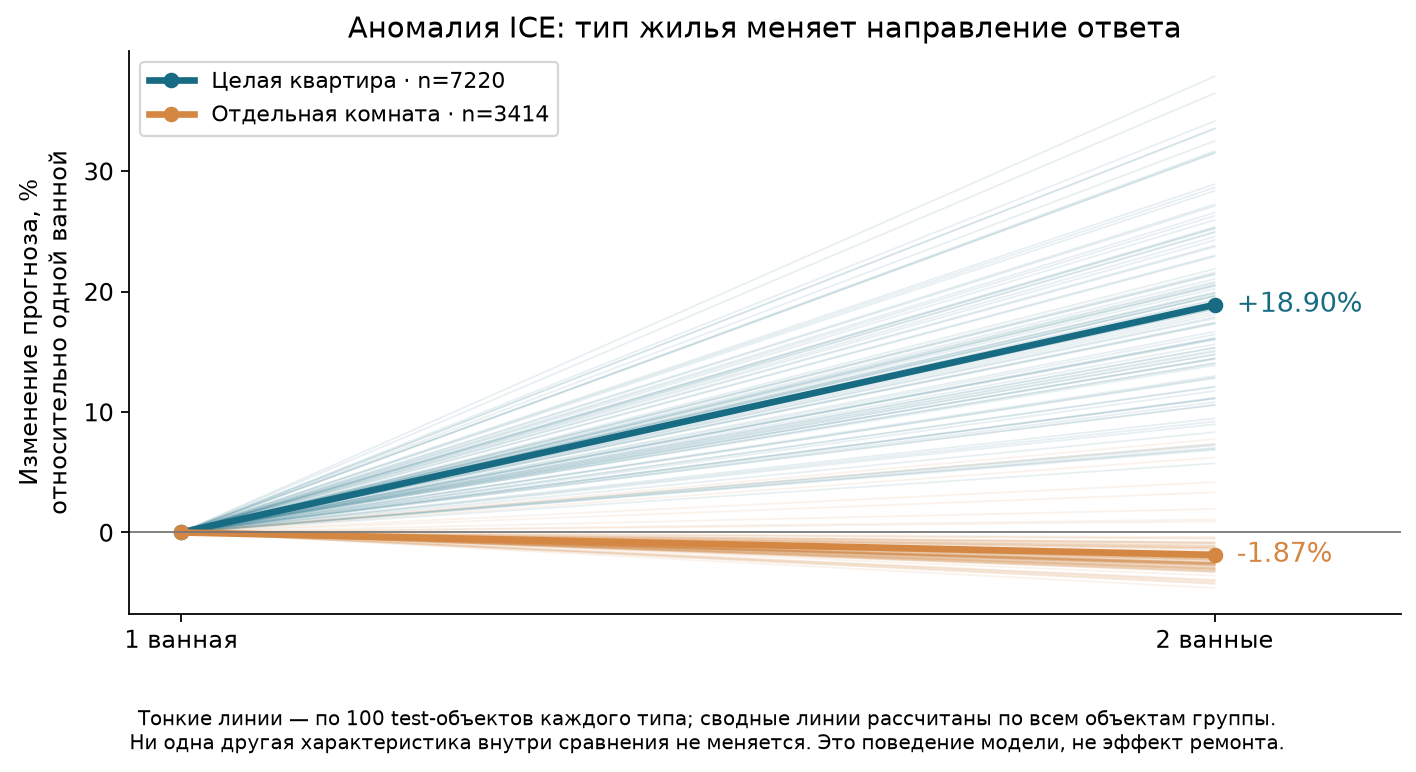

**Что обнаружилось.** На test XGBoost повышает прогноз для целой квартиры в среднем на **18,90%**, а для отдельной комнаты понижает на **1,87%**. Положительный ответ есть у всех целых объектов; отрицательный — примерно у 91% отдельных комнат. Для комнат отрицательный средний ответ сохраняется и при совместной ванной, и без признака совместности. Следующий график показывает, что на validation направление и величины близки: +19,15% и −1,88%. Исходная OLS даёт одинаковые +7,25% для обоих типов жилья.


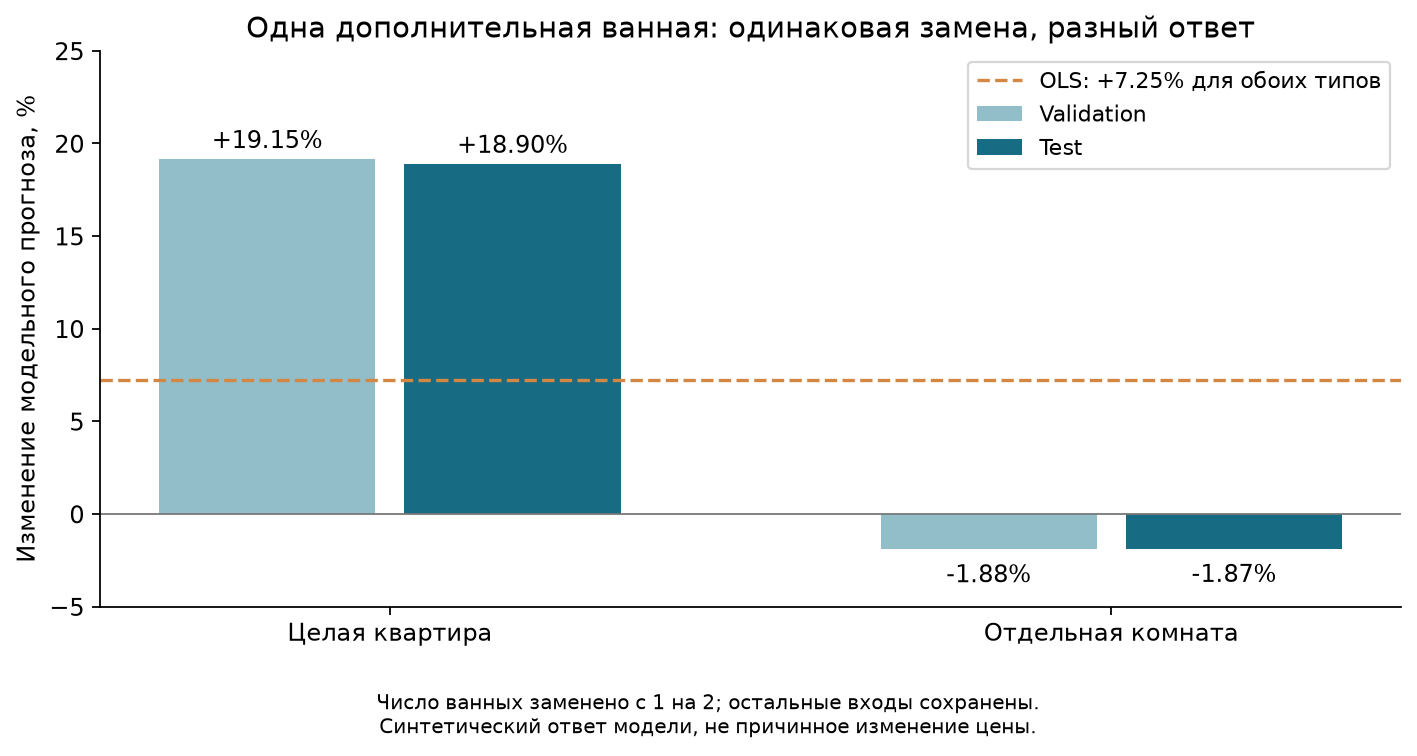

,Выборка,Тип жилья,Объектов,"XGBoost, %","OLS, %"
0,validation,Entire home/apt,6850,19.15,7.25
1,validation,Private room,3395,-1.88,7.25
2,holdout,Entire home/apt,7220,18.90,7.25
3,holdout,Private room,3414,-1.87,7.25


**Экономическая интерпретация.** При аренде целой квартиры дополнительная ванная означает дополнительные удобства: нескольким гостям проще пользоваться жильём одновременно. При аренде комнаты число ванных может описывать размер и устройство всего дома, включая формат совместного проживания. Поэтому одинаковая характеристика может иметь разный смысл в двух сегментах. Это возможное объяснение поведения модели; причинный механизм не установлен.

**Что бустинг учёл автоматически?** Он выучил, что связь числа ванных с прогнозом зависит от типа жилья и других характеристик объекта. Мы не задавали ему отдельное правило для квартир и комнат. На следующем графике это показано через SHAP-разложение: сверху — весь вклад числа ванных, снизу — его взаимодействие с типом жилья. Красные точки в обеих строках обозначают ровно две ванные; кружки — целые квартиры, треугольники — отдельные комнаты.


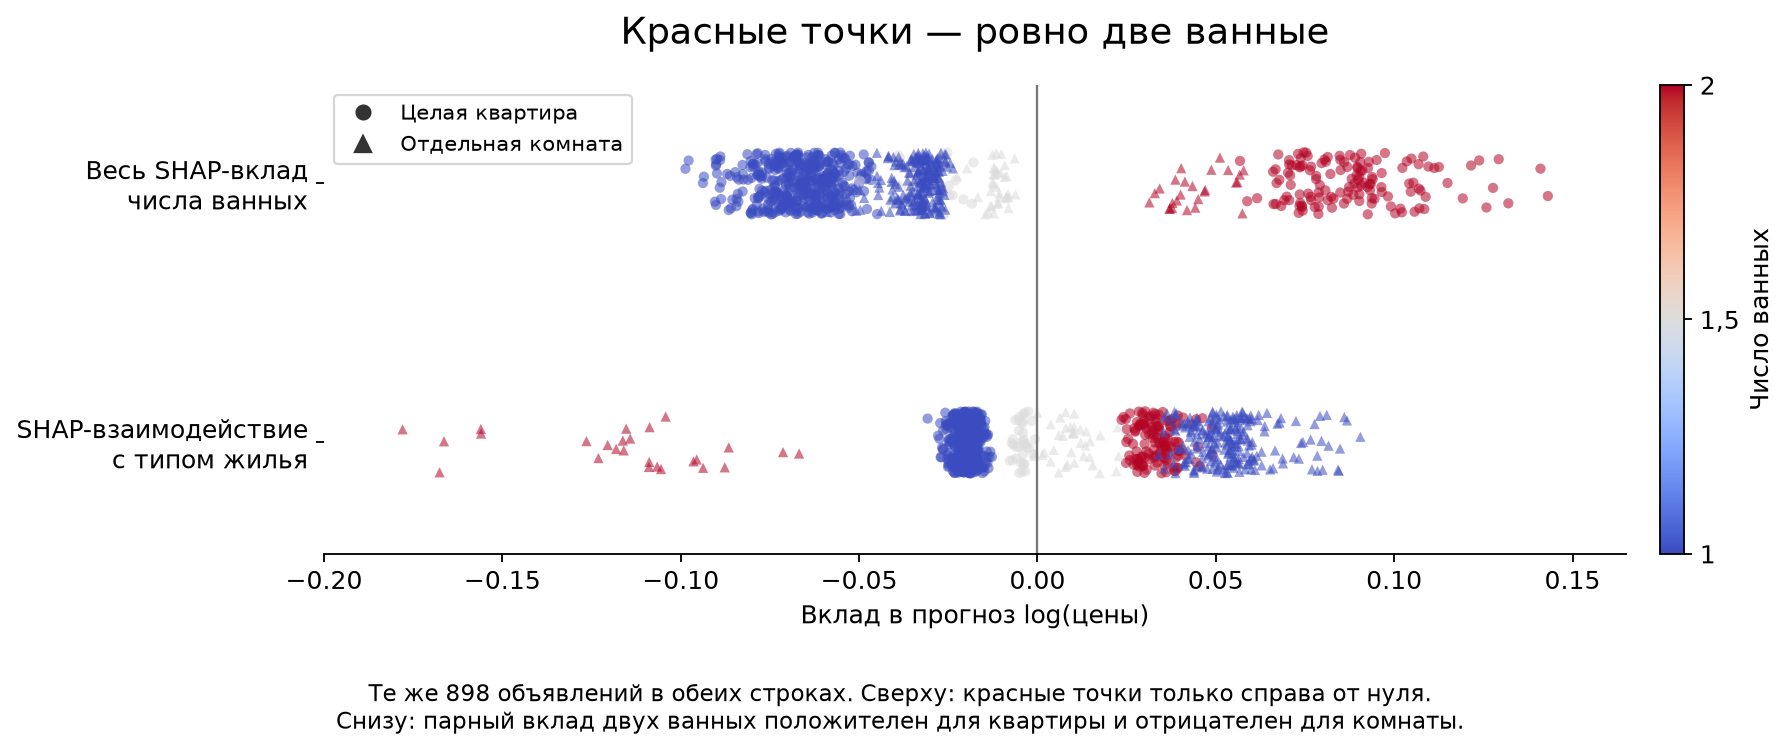

Сверху красные точки положительные в обоих сегментах. Снизу совместный вклад положителен для квартир и отрицателен для комнат. Поэтому полное SHAP-разложение и прямая реакция на замену входа — разные величины. Направление изменения прогноза мы проверили ICE выше; SHAP помогает выделить взаимодействие, которое стоит изучить.

**Почему стоит пробовать XGBoost вместе с линейной моделью?**

1. **Он автоматически учитывает нелинейные зависимости и взаимодействия.** В исходной OLS дополнительная ванная даёт одинаковую относительную прибавку для всех объектов, если соответствующее взаимодействие явно не добавлено. В XGBoost ответ может зависеть от типа жилья, а также меняться на разных участках шкалы признака. В нашем сравнении XGBoost точнее исходной OLS: test log MAE равна 0,25107 против 0,28082, примерно на 10,6% ниже. Гибкость даёт основание попробовать бустинг; её пользу нужно проверять на отложенных данных. Этот один график не устанавливает, какая часть выигрыша вызвана именно взаимодействиями.

2. **Разбор XGBoost помогает улучшать спецификацию линейной модели.** ICE и SHAP подсказывают, какие взаимосвязи стоит явно добавить в регрессию. В нашем случае это произведение `bathroom_count × I(room_type = Private room)`: индикатор равен 1 для отдельной комнаты и 0 для остальных объектов. Такой член позволяет коэффициенту числа ванных различаться между сегментами. Ниже исходная OLS сравнивается с вариантом, где добавлено только это взаимодействие; оба обучены на исходном train.


,Модель,Log MAE,"MAE, GBP"
3,OLS,0.28082,62.97825
4,OLS + bathroom_count x private room,0.27955,62.97209
5,XGBoost,0.25107,57.09949


Добавление взаимодействия снижает test log MAE с 0,28082 до 0,27955, примерно на 0,45%; на validation ошибка тоже уменьшается. Улучшение небольшое и не объясняет весь разрыв с XGBoost. Это пример того, как находку гибкой модели можно перенести в более простую регрессию.

Здесь исправляется **пропуск важной связи в спецификации**. Число ванных и тип жилья уже были включены; не хватало члена, описывающего их совместное действие. Это не гарантирует устранения смещения из-за ненаблюдаемых характеристик жилья, спроса или других пропущенных переменных. Найденные связи требуют отдельной проверки, особенно если их обнаружили после просмотра test.

Наблюдаемых объектов с двумя ванными в test — 1 601 среди целых квартир и 313 среди отдельных комнат. Это даёт опору для сравнения, но не гарантирует реалистичность каждого синтетического сочетания входов. Все новые находки и добавленное взаимодействие являются разведочными; статистическая значимость отдельно не проверялась. Ответ модели не оценивает реальный эффект строительства ванной.


In [18]:
from helpers.bathroom_case import bathroom_case
from helpers.ice_overview import bathroom_ice_focus
bathroom_response, bathroom_support = bathroom_case(
    d, X, pre, models['XGBoost'][1], models['OLS'][1])
bathroom_ice_focus()
figure('ice_bathroom_focus')
display(Markdown('**Что обнаружилось.** На test XGBoost повышает прогноз для целой квартиры в среднем на **18,90%**, а для отдельной комнаты понижает на **1,87%**. Положительный ответ есть у всех целых объектов; отрицательный — примерно у 91% отдельных комнат. Для комнат отрицательный средний ответ сохраняется и при совместной ванной, и без признака совместности. Следующий график показывает, что на validation направление и величины близки: +19,15% и −1,88%. Исходная OLS даёт одинаковые +7,25% для обоих типов жилья.\n'))
figure('bathroom_model_response')
display(bathroom_response[['split', 'room_type', 'n', 'xgb_change_pct', 'ols_change_pct']]
        .rename(columns={'split': 'Выборка', 'room_type': 'Тип жилья', 'n': 'Объектов',
                         'xgb_change_pct': 'XGBoost, %', 'ols_change_pct': 'OLS, %'})
        .round(2))
display(Markdown('**Экономическая интерпретация.** При аренде целой квартиры дополнительная ванная означает дополнительные удобства: нескольким гостям проще пользоваться жильём одновременно. При аренде комнаты число ванных может описывать размер и устройство всего дома, включая формат совместного проживания. Поэтому одинаковая характеристика может иметь разный смысл в двух сегментах. Это возможное объяснение поведения модели; причинный механизм не установлен.\n\n**Что бустинг учёл автоматически?** Он выучил, что связь числа ванных с прогнозом зависит от типа жилья и других характеристик объекта. Мы не задавали ему отдельное правило для квартир и комнат. На следующем графике это показано через SHAP-разложение: сверху — весь вклад числа ванных, снизу — его взаимодействие с типом жилья. Красные точки в обеих строках обозначают ровно две ванные; кружки — целые квартиры, треугольники — отдельные комнаты.\n'))
from helpers.bathroom_comparison import bathroom_shap_comparison, linear_interaction_check
bathroom_shap_comparison()
figure('bathroom_shap_comparison')
display(Markdown('Сверху красные точки положительные в обоих сегментах. Снизу совместный вклад положителен для квартир и отрицателен для комнат. Поэтому полное SHAP-разложение и прямая реакция на замену входа — разные величины. Направление изменения прогноза мы проверили ICE выше; SHAP помогает выделить взаимодействие, которое стоит изучить.\n\n**Почему стоит пробовать XGBoost вместе с линейной моделью?**\n\n1. **Он автоматически учитывает нелинейные зависимости и взаимодействия.** В исходной OLS дополнительная ванная даёт одинаковую относительную прибавку для всех объектов, если соответствующее взаимодействие явно не добавлено. В XGBoost ответ может зависеть от типа жилья, а также меняться на разных участках шкалы признака. В нашем сравнении XGBoost точнее исходной OLS: test log MAE равна 0,25107 против 0,28082, примерно на 10,6% ниже. Гибкость даёт основание попробовать бустинг; её пользу нужно проверять на отложенных данных. Этот один график не устанавливает, какая часть выигрыша вызвана именно взаимодействиями.\n\n2. **Разбор XGBoost помогает улучшать спецификацию линейной модели.** ICE и SHAP подсказывают, какие взаимосвязи стоит явно добавить в регрессию. В нашем случае это произведение `bathroom_count × I(room_type = Private room)`: индикатор равен 1 для отдельной комнаты и 0 для остальных объектов. Такой член позволяет коэффициенту числа ванных различаться между сегментами. Ниже исходная OLS сравнивается с вариантом, где добавлено только это взаимодействие; оба обучены на исходном train.\n'))
bathroom_linear_check = linear_interaction_check(d, X, pre, models['OLS'][1], models['XGBoost'][1])
display(bathroom_linear_check.loc[bathroom_linear_check.split.eq('holdout'), ['model', 'log_mae', 'gbp_mae']]
        .rename(columns={'model': 'Модель', 'log_mae': 'Log MAE', 'gbp_mae': 'MAE, GBP'}).round(5))
display(Markdown('Добавление взаимодействия снижает test log MAE с 0,28082 до 0,27955, примерно на 0,45%; на validation ошибка тоже уменьшается. Улучшение небольшое и не объясняет весь разрыв с XGBoost. Это пример того, как находку гибкой модели можно перенести в более простую регрессию.\n\nЗдесь исправляется **пропуск важной связи в спецификации**. Число ванных и тип жилья уже были включены; не хватало члена, описывающего их совместное действие. Это не гарантирует устранения смещения из-за ненаблюдаемых характеристик жилья, спроса или других пропущенных переменных. Найденные связи требуют отдельной проверки, особенно если их обнаружили после просмотра test.\n\nНаблюдаемых объектов с двумя ванными в test — 1 601 среди целых квартир и 313 среди отдельных комнат. Это даёт опору для сравнения, но не гарантирует реалистичность каждого синтетического сочетания входов. Все новые находки и добавленное взаимодействие являются разведочными; статистическая значимость отдельно не проверялась. Ответ модели не оценивает реальный эффект строительства ванной.\n'))


### 7.3. Меняется ли связь рейтинга с прогнозом при разном числе отзывов

Экономическая гипотеза предполагает, что более высокий рейтинг связан с большей ценовой премией, когда отзывов много. Проверяем, воспроизводит ли эту закономерность XGBoost, который допускает более сложные связи, чем линейная регрессия.

Здесь используем модель из второго эксперимента раздела 6: XGBoost с рейтингом, числом и частотой отзывов, обученный на выборке объявлений с наблюдаемым рейтингом. Это другая модель, чем основная прогнозная модель в разделах 7.1–7.2.

#### Что сравниваем

Случайно выбираем 1 000 объявлений из рейтингового test с рейтингом 4,5–5 и 5–150 отзывами. Для каждого объявления создаём четыре варианта входных данных: рейтинг 4,7 и 4,9 сначала при 10, затем при 100 отзывах. Остальные признаки, включая частоту отзывов, сохраняем. Модель не переобучаем.

При каждом числе отзывов вычитаем прогноз для рейтинга 4,7 из прогноза для 4,9. Усредняем разницы логарифмов и переводим результат в проценты по формуле `100 × (exp(средняя разница) − 1)`. Поэтому числа ниже показывают относительное изменение модельного прогноза при заданной смене входов.

| Число отзывов | Изменение прогноза при рейтинге 4,7 → 4,9 | Разброс индивидуальных изменений: 10–90-й процентили |
|---|---:|---:|
| 10 | +8,33% | от +4,15% до +13,17% |
| 100 | +8,96% | от +4,59% до +14,16% |

Направление совпадает с гипотезой, но разница составляет всего **0,63 процентного пункта**. Для сравнения, в основной OLS на рейтинговом test соответствующие значения равны 5,18% и 11,18%. Значит, величина различия заметно зависит от модели. Результат XGBoost даёт гораздо более слабое усиление премии при большом числе отзывов.

Процентили в таблице, обозначенные в выводе как `ice_q10_pct` и `ice_q90_pct`, показывают различия ответов между объявлениями. Это не доверительный интервал для средней премии: они не учитывают неопределённость обучения модели.

#### Зачем проверяем наличие похожих наблюдений

Чтобы не опираться только на вымышленные сочетания рейтинга и отзывов, считаем реальные объявления поблизости. Для рейтингов 4,7 и 4,9 допускаем отклонение ±0,05; для 10 отзывов берём диапазон 5–20, для 100 — 70–130. Получаем соответственно 371 и 479 объявлений в первой группе, 139 и 222 во второй.

На тепловой карте цвет показывает средний прогноз логарифма цены для сочетания рейтинга и числа отзывов. Клетки, возле которых найдено меньше 30 реальных объявлений, оставляем пустыми. Наличие наблюдений по двум показателям всё же не гарантирует реалистичность каждого сочетания с районом, качеством жилья и частотой отзывов.

Это проверка того, как отвечает обученная модель. Она не доказывает, что увеличение рейтинга вызовет такой рост цены, и не является отдельным статистическим подтверждением OLS. В частности, фиксированная частота при изменённом числе отзывов может создавать необычные сочетания характеристик.


,reviews,rating,n,review_low,review_high
0,10,4.7,371,5,20
1,10,4.9,479,5,20
2,100,4.7,139,70,130
3,100,4.9,222,70,130


,reviews,mean_delta_log,premium_pct,ice_q10_pct,ice_q90_pct,n
0,10,0.080005,8.329216,4.148721,13.171776,1000
1,100,0.085770,8.955606,4.590689,14.157015,1000


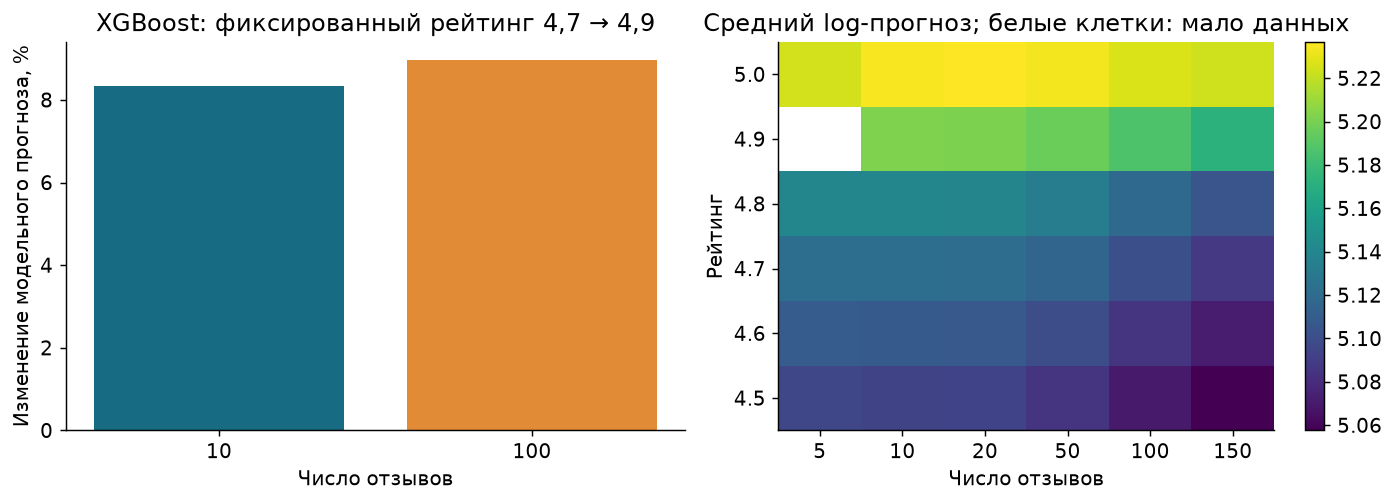

**Результат XGBoost:** премия больше при 100 отзывах: направление согласуется с OLS. Разница модельных премий — 0.63 процентного пункта: дополнительность в этом XGBoost заметно слабее, чем в OLS. Это описание одной обученной модели; SHAP и этот контраст не являются независимой проверкой значимости.

In [12]:
response, response_support = A.response(rated, rated_X, rated_models)
display(response_support)
display(response)
figure('response')
delta = response.set_index('reviews').mean_delta_log
message = ('больше при 100 отзывах: направление согласуется с OLS' if delta.loc[100] > delta.loc[10] else 'не больше при 100 отзывах: данный модельный контраст не подтверждает направление OLS')
display(Markdown('**Результат XGBoost:** премия '+message+'. ' + f'Разница модельных премий — {response.premium_pct.iloc[1]-response.premium_pct.iloc[0]:.2f} процентного пункта: дополнительность в этом XGBoost заметно слабее, чем в OLS.' + ' Это описание одной обученной модели; SHAP и этот контраст не являются независимой проверкой значимости.'))


### 7.4. Примеры прогнозов и группы, в которых модель чаще ошибается

Теперь переходим от общей картины к отдельным объявлениям. Код автоматически выбирает три объекта из SHAP-выборки: с абсолютной log-ошибкой около 25-го, 50-го и 90-го процентилей. Это примеры относительно небольшой, средней и большой ошибки; мы не выбирали их вручную по удобству объяснения.

| Пример по величине ошибки | Настоящая цена | Прогноз XGBoost |
|---|---:|---:|
| Около 25-го процентиля | £78,00 | £85,25 |
| Около 50-го процентиля | £154,83 | £186,20 |
| Около 90-го процентиля | £350,83 | £209,19 |

На каждом графике показаны шесть самых больших по модулю SHAP-вкладов и сумма остальных (`Other features`). Вклад вправо повышает log-прогноз относительно базы, влево — понижает. Если сложить все столбцы с базовым значением, получится прогноз этого объявления. Так можно понять, какие свойства модель учла, и увидеть, что даже понятное объяснение не гарантирует точного прогноза: в третьем примере цена сильно недооценена.

В таблице `local_examples` столбец `error_log` хранит подписанную ошибку: положительное значение означает завышение прогноза, отрицательное — занижение. Для выбора примеров использован её модуль. Столбцы `base_log` и `contribution_sum` позволяют проверить сложение базы и вкладов.

#### Где качество ниже

Последняя таблица пересчитывает ошибки на всём исходном test из 11 904 объявлений, а не только на трёх примерах или 1 000 объектах SHAP. Объявления разбиты по типу комнаты, настоящей цене и числу отзывов. В каждой группе `n` — число объектов, `log_mae` — средняя ошибка логарифма цены, `gbp_mae` — средняя абсолютная ошибка в фунтах.

Для объектов дороже £400 средняя ошибка составляет £219,67 (1 251 объявление). У объектов не дороже £100 она равна £20,03. Дорогие объекты сложнее предсказывать и в log-шкале: 0,432 против 0,258. Одной разницей цен эти ошибки в фунтах не объясняются.

Объявления без отзывов тоже предсказываются хуже: log MAE равна 0,338 против 0,213 у объявлений со 101 и более отзывами. Это описание групп; оно не доказывает, что добавление отзывов само по себе улучшит прогноз. Группы могут различаться и по другим свойствам.

У гостиничных и общих комнат log MAE особенно высока, но в test их всего 44 и 52. Такие средние менее устойчивы. Все эти сравнения показывают, где общей метрики недостаточно для оценки качества; отдельные статистические тесты различий между группами здесь не проводятся.


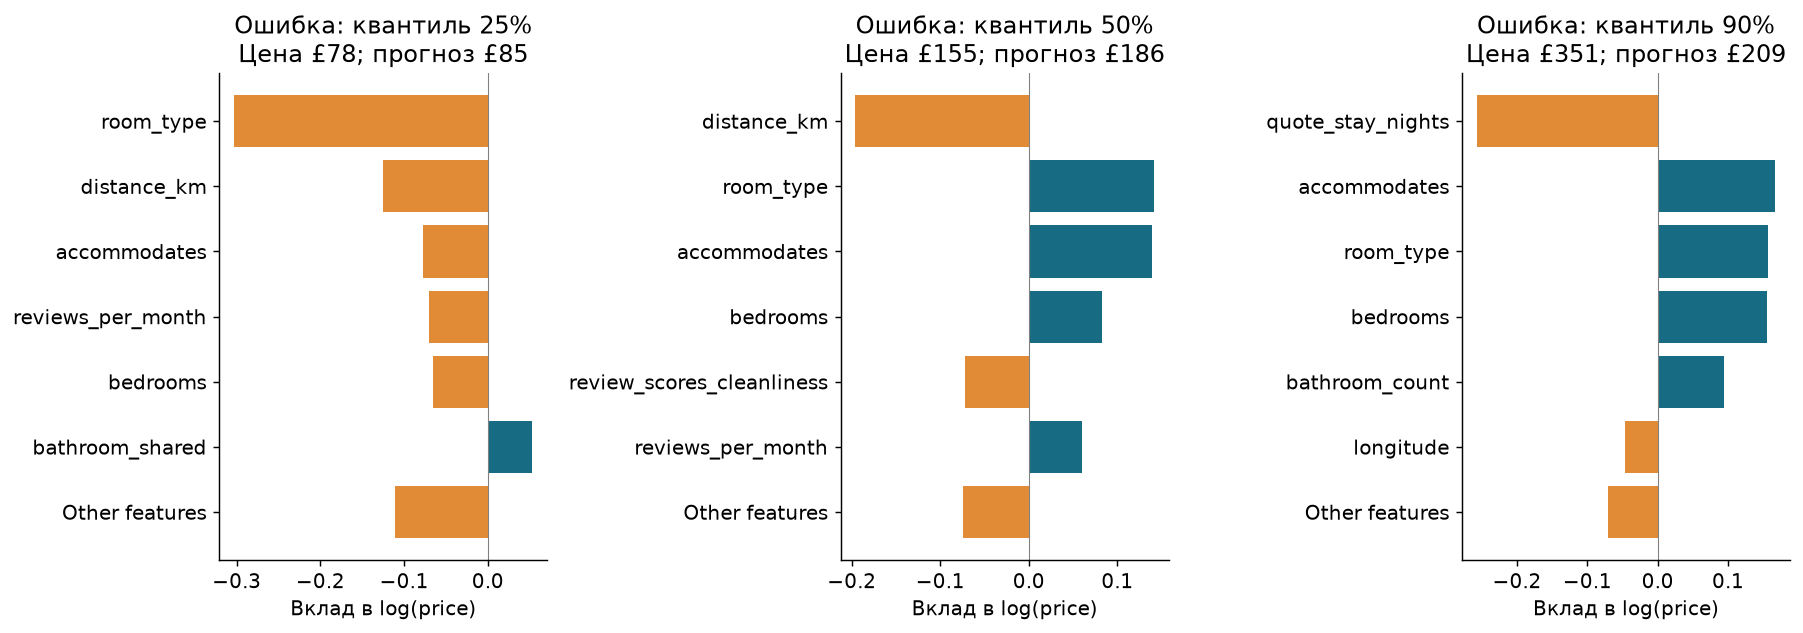

,id,host_id,room_type,price_gbp,review_scores_rating,number_of_reviews,prediction_log,base_log,error_log,selection_error_quantile,contribution_sum,top_features
0,1569642699738706391,581743235,Private room,78.00,4.80,30,4.445594,5.14436,0.088885,0.25,-0.698765,room_type; distance_km; accommodates; reviews_...
1,44412309,263279068,Entire home/apt,154.83,4.57,7,5.226836,5.14436,0.184508,0.50,0.082472,distance_km; room_type; accommodates; bedrooms...
2,1570387236912584343,662764354,Entire home/apt,350.83,5.00,13,5.343262,5.14436,-0.517040,0.90,0.198903,quote_stay_nights; accommodates; room_type; be...


,dimension,group,n,log_mae,gbp_mae
0,room_type,Entire home/apt,8006,0.236610,68.343983
1,room_type,Hotel room,44,0.460833,125.259133
2,room_type,Private room,3802,0.275361,32.931026
3,room_type,Shared room,52,0.522758,35.294078
0,price_band,≤100,3040,0.258034,20.027498
1,price_band,100–200,3948,0.217597,34.067975
2,price_band,200–400,3665,0.219504,57.167297
3,price_band,400–2000,1251,0.432217,219.672488
0,review_band,0,2167,0.337630,87.728097
1,review_band,1–10,4146,0.246594,54.523375


In [13]:
figure('local_explanations')
display(pd.read_csv(A.OUT/'local_examples.csv'))
errors = A.error_audit(predictions['holdout'])
display(errors)


## 8. Что мы узнали и насколько далеко идут выводы

Проект отвечает на несколько связанных вопросов, и для каждого нужен свой результат.

**Насколько точно можно предсказывать цену?** На исходном test из 11 904 объявлений средняя абсолютная ошибка XGBoost составляет £57,10, у Ridge — £62,97. XGBoost точнее примерно на £5,87 в среднем. Его log MAE равна 0,2511. Ошибка £57,10 не означает, что каждый прогноз отличается от цены именно на эту сумму: раздел 7.4 показывает существенные различия между группами.

**Поддерживает ли линейная регрессия гипотезу об отзывах?** В основной OLS на рейтинговом test переход 4,7 → 4,9 связан с премией 5,18% при 10 отзывах и 11,18% при 100. Проверяется различие этих связей с учётом остальных признаков. Большинство предусмотренных проверок поддерживает направление, однако сентябрьская проверка внутри одного хозяина не проходит поправку на 21 гипотезу. Июньские данные также поддерживают направление, но это более ранний, уже изученный снимок того же города. Эти результаты нельзя считать новой проверкой на нетронутых данных.

**Помогает ли взаимодействие прогнозу?** В OLS добавление произведения рейтинга и log-числа отзывов после самих показателей отзывов снижает log MAE с 0,24885 до 0,24568, примерно на 1,28%. Значит, обнаруженная статистическая связь даёт небольшой дополнительный выигрыш в прогнозе.

**Воспроизводит ли XGBoost такой же масштаб различия?** Модельный ответ равен +8,33% при 10 отзывах и +8,96% при 100. Направление совпадает с OLS, но разница значительно меньше. Поэтому утверждать, что точный размер усиления премии устойчив к выбору модели, оснований нет.

Код ниже собирает основные числа из сохранённых в этом запуске расчётов. Сопоставлять их нужно с оговорками о выборках и методах выше: прогнозные модели и регрессионные проверки решают разные задачи.


In [14]:
test = model_scores.query("split=='holdout'").set_index('model')
old = ols_contrasts.query("analysis=='september' and spec=='primary' and split=='holdout'").set_index('comparison')
a10=old.loc['rating_plus_02_at_10_reviews','pct_change']; a100=old.loc['rating_plus_02_at_100_reviews','pct_change']
matched=ablation.query("split=='holdout' and model=='OLS'").set_index('features')
gain=matched.loc['Review main','log_mae']-matched.loc['Review interaction','log_mae']
display(Markdown(f"""* **Прогноз:** XGBoost log MAE = {test.loc['XGBoost','log_mae']:.4f}, GBP MAE = £{test.loc['XGBoost','gbp_mae']:.2f}; Ridge £{test.loc['Ridge','gbp_mae']:.2f} на тех же {len(ix['holdout']):,} объектах.
* **OLS:** на старом сентябрьском test премия за рейтинг 4,7 → 4,9 равна {a10:.2f}% при 10 и {a100:.2f}% при 100 отзывах. Проверяется разность, а не различие между двумя p-values.
* **Практическая роль взаимодействия:** добавление произведения к matched OLS изменяет log MAE на {gain:+.5f} (положительное число означает улучшение). Значимость и точность решают разные задачи.
* **XGBoost:** {message}. Модельный ответ не меняет статус регрессионной проверки и не объясняет причину связи.
* **Ограничение устойчивости:** один сентябрьский within-host test не проходит поправку на 21 гипотезу. Июньские результаты и данные других хозяев анализируются отдельно.
"""))


* **Прогноз:** XGBoost log MAE = 0.2511, GBP MAE = £57.10; Ridge £62.97 на тех же 11,904 объектах.
* **OLS:** на старом сентябрьском test премия за рейтинг 4,7 → 4,9 равна 5.18% при 10 и 11.18% при 100 отзывах. Проверяется разность, а не различие между двумя p-values.
* **Практическая роль взаимодействия:** добавление произведения к matched OLS изменяет log MAE на +0.00318 (положительное число означает улучшение). Значимость и точность решают разные задачи.
* **XGBoost:** больше при 100 отзывах: направление согласуется с OLS. Модельный ответ не меняет статус регрессионной проверки и не объясняет причину связи.
* **Ограничение устойчивости:** один сентябрьский within-host test не проходит поправку на 21 гипотезу. Июньские результаты и данные других хозяев анализируются отдельно.


### Какой экономический вывод можно защитить

Данные согласуются с предположением, что рейтинг связан с ценой сильнее при большем числе отзывов. Это подходит к объяснению через доверие гостей: оценка, основанная на большем числе отзывов, может быть убедительнее. Однако мы не измеряли доверие напрямую и не отделили его от других объяснений.

Отзывы могут отражать качество жилья, возраст объявления и прошлый спрос. Спрос и предыдущие цены, в свою очередь, влияют на то, сколько отзывов накопится. Поэтому число отзывов нельзя считать случайно заданным. Даже после учёта наблюдаемых характеристик часть этих связей может сохраниться.

Есть и ограничение данных: известна цена предложения для конкретного периода, а не цена состоявшейся сделки. Мы анализируем объявления с наблюдаемой ценой в выбранном диапазоне. Если отсутствие цены связано с активностью хозяина или календарём, результаты могут не описывать остальные объявления.

Для проекта можно обосновать два результата: сравнение точности моделей и условную связь рейтинга с ценой, которая зависит от числа отзывов. По этим расчётам нельзя определить, сколько хозяин заработает после новых отзывов, или какую долю премии создаёт доверие гостей. Для этого нужны данные о бронированиях и исследовательский подход, позволяющий отделить изменение отзывов от качества и спроса. Проверка на действительно новых датах или городах отдельно помогла бы оценить переносимость найденных закономерностей.


## 9. Как проверить расчёты и подготовиться к защите

Последняя ячейка запускает `helpers/verify.py`. Скрипт сверяет сохранённые результаты между собой и заново считает ряд показателей. Значение `True` означает, что соответствующие программные проверки прошли; при нарушении условия выполнение останавливается с ошибкой.

Проверяется следующее:

- Контрольные суммы исходных файлов совпадают с записанными; данные не изменились незаметно.
- Объявления одного хозяина не попали одновременно в train, validation и test. В GroupKFold один хозяин также не распределён по разным частям.
- В перечне входов нет явно запрещённых признаков, перечисленных в аудите.
- Ошибки и R² заново рассчитаны из сохранённых прогнозов и совпадают с итоговой таблицей.
- Регрессионные сравнения и интервалы совпадают с сохранёнными коэффициентами и матрицами их неопределённости.
- SHAP-вклады вместе с базой дают прогнозы модели. Размеры июньских выборок и наличие всех 40 регрессионных проверок соответствуют ожидаемым. В том числе сохранена проверка, не поддержавшая гипотезу.

Этот скрипт не обучает модели заново. Даже строка `all_40_inference_fits_recomputed` в выводе здесь означает проверку наличия и согласованности сохранённых результатов; сами регрессии рассчитываются в предыдущих ячейках. Полное воспроизведение требует выполнения всего ноутбука с начала. Успех проверок подтверждает внутреннюю согласованность расчётов, но сам по себе не доказывает экономическую гипотезу или причинный эффект.

#### Что использовать при подготовке выступления

Ноутбук содержит расчёты и объяснения; презентация `london_airbnb_group_project.pptx` и её PDF-версия — материал для выступления. В `speaker_notes.txt` записаны заметки к слайдам. Подробные коэффициенты и проверки вынесены в приложение презентации.

Шесть тематических частей презентации I–VI — это порядок рассказа: задача, данные, линейные модели, XGBoost, проверки и выводы. Задачи четырёх участников описаны отдельно в [плане проверки проекта](https://github.com/OsVox/london-airbnb-economics/blob/main/docs/team-review-four-parts.docx).

Перед защитой стоит сверить числа в ноутбуке, таблицах и слайдах, затем провести две репетиции и оставить время на правки. Репетиции ещё не проводились; имена участников в материалы не добавлены.


In [15]:
from helpers.verify import verify
checks = verify()
display(pd.Series(checks))
print('Numerical artifacts:', len(list(A.OUT.rglob('*.csv'))), 'CSV files')


data_hashes                          True
host_disjoint                        True
forbidden_inputs_excluded            True
all_prediction_metrics_recomputed    True
all_ols_contrasts_full_covariance    True
all_40_inference_fits_recomputed     True
known_failed_check_retained          True
june_cohorts_verified                True
shap_additivity                      True
cv_host_separation                   True
dtype: bool

Numerical artifacts: 54 CSV files
